# Regression and Classification: Error Analysis on the Indian Used-Car Market
## Homework Assignment 2

| | |
|---|---|
| **Student name** | Ishay Hanufa |
| **ID number** | 322368796 |
| **Course** | Introduction to Data Science, HIT — Dr. Uri Itai, TA: Hanit Ohayon Hadad |
| **Dataset** | `used_cars_data.csv` — the same 7,253 used-car listings analysed in Assignment 1 ([Kaggle](https://www.kaggle.com/datasets/ayushparwal2026/cars-dataset)) |

**Goal.** Not only to build models that predict the price of a used car, but to understand **where, how and why they fail** — and whether each failure comes from the **data**, from the **model's assumptions**, or from the **way the problem is formulated**.

* **Regression task:** predict the used-car price (INR Lakh).
* **Classification task:** predict whether a car is **expensive** — priced above the median of the data (5.64 Lakh).

All results are computed with **k-fold cross-validation**: every error analysed below is an *out-of-fold* error, i.e. made on cars the model did not see during training.

> **Executive answer.** Yes — the listing information predicts the price well, but not equally well for every car. The best model (**Gradient Boosting on log-price**) explains 95% of the variance in log-price, with a typical (median) error of ~10% of the price (MAE 1.39 Lakh), against ~55% for a baseline that always predicts the average price. The best classifier separates expensive and cheap cars with ROC-AUC 0.981 and 92% accuracy. The errors are concentrated in **rare and luxury brands**, **very old cars**, the **extremes of the price range** (where predictions are pulled towards the average) and, for classification, in cars priced **close to the median threshold**. Several of the largest "errors" are actually **implausible listings** (e.g. a 2019 Porsche Cayenne at 2 Lakh), where the model is right and the label is wrong.

### Assignment coverage map
| Assignment requirement | Section |
|---|---|
| Choice and justification of *k* | 2 |
| Regression models (Linear, Decision Tree, Random Forest, Gradient Boosting + bonus KNN, SVR, plus a mean baseline), hyper-parameters, multiple metrics, train vs validation error | 3 |
| 1.1 Residual analysis (residuals vs predicted, distribution, centring, patterns, heteroscedasticity, sectors) | 4.1 |
| 1.2 Error as a function of features | 4.2 |
| 1.3 Top 5% extreme errors | 4.3 |
| 1.4 MAE, residual std, skewness, kurtosis | 4.4 |
| Regression discussion | 4.5 |
| 3.1 Confusion matrix, FP/FN | 6.1 |
| 3.2 Probabilities of correct vs incorrect predictions | 6.2 |
| 3.3 Error as a function of features | 6.3 |
| 3.4 Thresholds 0.1–0.9, precision/recall/F1, F-beta vs beta, MCC, ROC-AUC | 6.4 |
| 3.5 Classification discussion | 6.5 |
| 4 Final reflection | 7 |
| Reproducibility and automated checks | 8 |

## 1. Setup, Data Preparation and Shared Helpers

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, fbeta_score,
                             matthews_corrcoef, mean_absolute_error, mean_squared_error,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold", "axes.titlesize": 13})

# ---- Project constants ------------------------------------------------------
DATA_FILE_NAME = "used_cars_data.csv"
CANDIDATE_DATA_PATHS = [os.path.join("data", DATA_FILE_NAME), DATA_FILE_NAME]
DATA_PATH = next((path for path in CANDIDATE_DATA_PATHS if os.path.isfile(path)), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"'{DATA_FILE_NAME}' was not found in {os.getcwd()} or its 'data' subfolder.")

RANDOM_STATE = 42
N_FOLDS = 5                        # justified in Section 2
DATA_REFERENCE_YEAR = 2019         # newest model year in the data (Assignment 1)
MAX_PLAUSIBLE_KM = 1_000_000
LAKH_PER_CRORE = 100
TOP_ERROR_SHARE = 0.05             # 'top 5% largest absolute errors'
THRESHOLDS = np.round(np.arange(0.1, 1.0, 0.1), 1)

In [2]:
# ---- Cleaning (same rules as in Assignment 1) ------------------------------------
BRAND_NAME_FIXES = {"land": "Land Rover", "isuzu": "Isuzu", "mini": "Mini", "opelcorsa": "Opel",
                    "mercedes-benz": "Mercedes-Benz", "bmw": "BMW"}
OWNER_ORDER = ["First", "Second", "Third", "Fourth & Above"]


def extract_leading_number(text_series: pd.Series) -> pd.Series:
    """'998 CC' -> 998.0 ; placeholders such as 'null bhp' -> NaN."""
    return pd.to_numeric(text_series.astype("string").str.split().str[0], errors="coerce")


def load_clean_cars(path: str) -> pd.DataFrame:
    """Load the raw file, parse text-with-unit columns and neutralize placeholders (see Assignment 1)."""
    raw = pd.read_csv(path).set_index("S.No.")
    cars = raw.copy()
    first_word = cars["Name"].str.split().str[0].str.lower()
    cars["Brand"] = first_word.map(BRAND_NAME_FIXES).fillna(first_word.str.title())
    model_position = np.where(first_word == "land", 2, 1)
    cars["Model"] = cars["Brand"] + " " + pd.Series(
        [words[pos] if len(words) > pos else "" for words, pos in zip(cars["Name"].str.split(), model_position)],
        index=cars.index).str.title()
    cars["Engine_CC"] = extract_leading_number(cars["Engine"])
    cars["Power_bhp"] = extract_leading_number(cars["Power"])
    cars["Mileage_value"] = extract_leading_number(cars["Mileage"]).replace(0, np.nan)
    new_price_unit = cars["New_Price"].astype("string").str.split().str[1].map({"Lakh": 1, "Cr": LAKH_PER_CRORE})
    cars["New_Price_Lakh"] = extract_leading_number(cars["New_Price"]) * new_price_unit
    cars["Seats"] = cars["Seats"].replace(0, np.nan)
    cars["Raw_Kilometers"] = cars["Kilometers_Driven"]                        # kept for error diagnosis
    cars.loc[cars["Kilometers_Driven"] > MAX_PLAUSIBLE_KM, "Kilometers_Driven"] = np.nan
    cars["Car_Age"] = DATA_REFERENCE_YEAR - cars["Year"]
    cars["Log_Kilometers"] = np.log(cars["Kilometers_Driven"])
    cars["Owner_Count"] = cars["Owner_Type"].map({name: rank + 1 for rank, name in enumerate(OWNER_ORDER)})
    return cars


all_cars = load_clean_cars(DATA_PATH)
cars = all_cars[all_cars["Price"].notna()].copy()        # the 1,234 unpriced rows (competition test set) cannot be used
cars["Log_Price"] = np.log(cars["Price"])
PRICE_MEDIAN = cars["Price"].median()
cars["Is_Expensive"] = (cars["Price"] > PRICE_MEDIAN).astype(int)

print(f"Priced rows used for modelling: {len(cars):,}")
print(f"Median price (classification threshold): {PRICE_MEDIAN:.2f} Lakh | "
      f"share of expensive cars: {cars['Is_Expensive'].mean():.1%}")

Priced rows used for modelling: 6,019
Median price (classification threshold): 5.64 Lakh | share of expensive cars: 49.9%


### Feature set
**All models use exactly the same features** (a requirement of the assignment), chosen from the findings of Assignment 1:

| Type | Features | Pre-processing (inside the CV pipeline) |
|---|---|---|
| Numerical | `Car_Age`, `Log_Kilometers`, `Power_bhp`, `Engine_CC`, `Mileage_value`, `Seats`, `Owner_Count` | median imputation → standardization |
| Categorical | `Brand`, `Location`, `Fuel_Type`, `Transmission` | one-hot encoding; categories with < 5 rows are merged into an "infrequent" level |

* **Target for regression:** `log(Price)`. Assignment 1 showed that price is strongly right-skewed and that depreciation is *multiplicative* (a constant % per year). Modelling the log makes the relationship closer to linear and the errors closer to constant variance. Predictions are converted back to Lakh (`exp`) for the business-scale metrics.
* **Leakage control:** imputation, scaling and encoding are fitted **inside each training fold only** (scikit-learn `Pipeline`). `New_Price` is **not** used — it is 86% missing and partly reveals the answer.
* `Model` (224 levels) is not used as a feature, but it is used later to diagnose errors.

In [3]:
NUMERIC_FEATURES = ["Car_Age", "Log_Kilometers", "Power_bhp", "Engine_CC", "Mileage_value", "Seats", "Owner_Count"]
CATEGORICAL_FEATURES = ["Brand", "Location", "Fuel_Type", "Transmission"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES


def build_preprocessor() -> ColumnTransformer:
    """Imputation + scaling for numbers, one-hot for categories — fitted inside every training fold."""
    numeric_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical_encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5)
    return ColumnTransformer([("numeric", numeric_pipeline, NUMERIC_FEATURES),
                              ("categorical", categorical_encoder, CATEGORICAL_FEATURES)])


def make_pipeline(model) -> Pipeline:
    """Attach the shared pre-processing to a model."""
    return Pipeline([("preprocess", build_preprocessor()), ("model", model)])


features = cars[FEATURES]
log_price = cars["Log_Price"]
is_expensive = cars["Is_Expensive"]
print(f"Feature matrix: {features.shape[0]:,} rows x {features.shape[1]} raw features "
      f"-> {make_pipeline(LinearRegression()).fit(features, log_price)[0].transform(features).shape[1]} columns after encoding")

Feature matrix: 6,019 rows x 11 raw features -> 50 columns after encoding


## 2. Choosing *k* for k-fold Cross-Validation

Considerations for *k*:
* **Dataset size.** With 6,019 rows, a validation fold of 1/k of the data must still contain enough cars from rare segments (luxury brands, CNG, third owners) to measure error reliably. k = 5 → ~1,200 cars per fold; k = 20 → only ~300.
* **Bias of the estimate.** Each model is trained on (k−1)/k of the data. Small *k* (e.g. 3 → 67%) trains on noticeably less data and gives a *pessimistic* (biased) estimate; k ≥ 5 trains on ≥ 80%.
* **Variance of the estimate.** Larger *k* gives fold scores that are more correlated and folds that are smaller and noisier.
* **Computation.** The cost grows linearly with *k*; the Random Forest and Gradient Boosting models are the expensive ones.

The experiment below measures these effects directly with a fast model (linear regression) and a slower one (gradient boosting):

In [4]:
def cv_rmse_for_k(model, n_folds: int) -> dict:
    """Mean / std of RMSE (log-price) across folds and the total run time for a given k."""
    folds = KFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    start = time.perf_counter()
    scores = -cross_val_score(make_pipeline(model), features, log_price, cv=folds,
                              scoring="neg_root_mean_squared_error")
    return {"k": n_folds, "train share": 1 - 1 / n_folds, "rows per validation fold": len(cars) // n_folds,
            "mean RMSE (log)": scores.mean(), "std RMSE across folds": scores.std(),
            "seconds": time.perf_counter() - start}


K_CANDIDATES = [3, 5, 10, 20]
k_experiment = pd.concat({
    "Linear Regression": pd.DataFrame([cv_rmse_for_k(LinearRegression(), k) for k in K_CANDIDATES]),
    "Gradient Boosting": pd.DataFrame([cv_rmse_for_k(
        GradientBoostingRegressor(n_estimators=200, max_depth=4, random_state=RANDOM_STATE), k) for k in K_CANDIDATES]),
}).droplevel(1).reset_index(names="model")
k_experiment

,model,k,train share,rows per validation fold,mean RMSE (log),std RMSE across folds,seconds
0,Linear Regression,3,0.667,2006,0.244,0.010,0.504
1,Linear Regression,5,0.800,1203,0.243,0.012,0.661
2,Linear Regression,10,0.900,601,0.243,0.018,1.053
3,Linear Regression,20,0.950,300,0.242,0.024,2.489
4,Gradient Boosting,3,0.667,2006,0.204,0.007,9.928
5,Gradient Boosting,5,0.800,1203,0.198,0.013,20.835
6,Gradient Boosting,10,0.900,601,0.197,0.017,43.323
7,Gradient Boosting,20,0.950,300,0.197,0.024,123.162


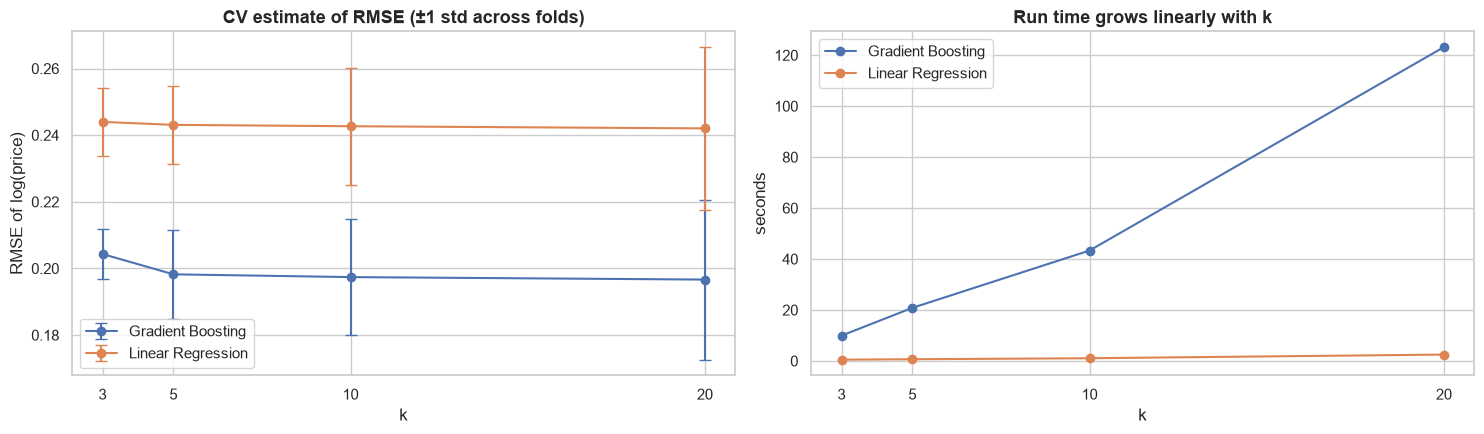

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for model_name, group in k_experiment.groupby("model"):
    axes[0].errorbar(group["k"], group["mean RMSE (log)"], yerr=group["std RMSE across folds"],
                     marker="o", capsize=4, label=model_name)
    axes[1].plot(group["k"], group["seconds"], marker="o", label=model_name)
axes[0].set_title("CV estimate of RMSE (±1 std across folds)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("RMSE of log(price)")
axes[1].set_title("Run time grows linearly with k")
axes[1].set_xlabel("k"); axes[1].set_ylabel("seconds")
for axis in axes:
    axis.set_xticks(K_CANDIDATES); axis.legend()
plt.tight_layout()
plt.show()

**Choice: k = 5.**
* **Bias:** k = 3 is visibly pessimistic for the flexible model (Gradient Boosting RMSE 0.204 vs 0.198) because each model sees only 67% of the data. From k = 5 onwards the estimate no longer improves (0.198 → 0.197), so training on 80% is already enough.
* **Variance:** the fold-to-fold standard deviation *grows* with k (0.013 at k = 5 → 0.024 at k = 20), because the validation folds become small (300 cars at k = 20) and each contains very few luxury or rare cars.
* **Computation:** the cost grows linearly with k — a Gradient Boosting run takes about 4–5× longer at k = 20 than at k = 5 (see the timing plot). The analysis below runs ~12 models, so k = 5 keeps the whole notebook fast.
* **Error analysis:** ~1,200 cars per validation fold is enough to study errors inside sub-groups (brands, cities, fuel types).

Folds are **shuffled** (the file order contains the train/test block structure found in Assignment 1) with a fixed `random_state` for reproducibility. For classification, **stratified** folds keep the 50/50 class balance in every fold.

## 3. Regression Models

| Model | Why it is included | Hyper-parameters |
|---|---|---|
| **Mean baseline** (`DummyRegressor`) | Sanity check — always predicts the training-fold mean; any useful model must beat it | `strategy="mean"` |
| **Linear Regression** | Baseline; assumes a linear, additive relationship with constant error variance | default (OLS) |
| **Decision Tree** | Non-linear, captures interactions; high variance | `max_depth=10`, `min_samples_leaf=5` (depth chosen with the validation curve below) |
| **Random Forest** | Averages many de-correlated trees → lower variance | `n_estimators=200`, `min_samples_leaf=2`, `max_features=0.5` |
| **Gradient Boosting** | Sequentially corrects errors → lower bias | `n_estimators=400`, `learning_rate=0.05`, `max_depth=4`, `subsample=0.8` |
| **KNN** *(bonus)* | Distance-based, no model of the relationship | `n_neighbors=7`, distance-weighted |
| **SVR** *(bonus)* | Kernel method, robust ε-insensitive loss | RBF kernel, `C=3`, `epsilon=0.05` |

First, a quick **validation curve** justifies the depth of the single decision tree and illustrates the bias–variance trade-off:

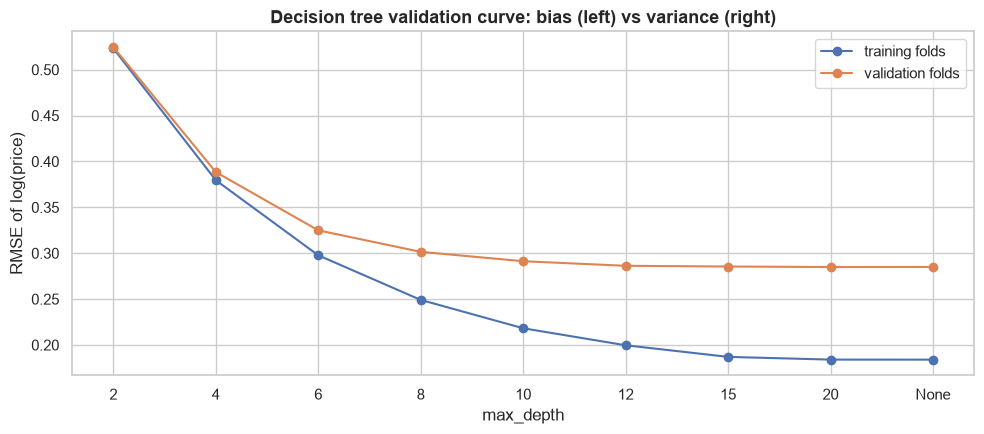

,max_depth,train RMSE,validation RMSE
0,2,0.523,0.525
1,4,0.379,0.388
2,6,0.298,0.325
3,8,0.249,0.301
4,10,0.218,0.291
5,12,0.200,0.286
6,15,0.187,0.285
7,20,0.184,0.285
8,None,0.184,0.285


In [6]:
TREE_DEPTHS = [2, 4, 6, 8, 10, 12, 15, 20, None]
depth_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
depth_rows = []
for depth in TREE_DEPTHS:
    tree_pipeline = make_pipeline(DecisionTreeRegressor(max_depth=depth, min_samples_leaf=5, random_state=RANDOM_STATE))
    train_rmse, valid_rmse = [], []
    for train_index, valid_index in depth_folds.split(features):
        tree_pipeline.fit(features.iloc[train_index], log_price.iloc[train_index])
        train_rmse.append(mean_squared_error(log_price.iloc[train_index], tree_pipeline.predict(features.iloc[train_index])) ** 0.5)
        valid_rmse.append(mean_squared_error(log_price.iloc[valid_index], tree_pipeline.predict(features.iloc[valid_index])) ** 0.5)
    depth_rows.append({"max_depth": "None" if depth is None else depth,
                       "train RMSE": np.mean(train_rmse), "validation RMSE": np.mean(valid_rmse)})
depth_curve = pd.DataFrame(depth_rows)

figure, axis = plt.subplots(figsize=(10, 4.5))
axis.plot(depth_curve["max_depth"].astype(str), depth_curve["train RMSE"], marker="o", label="training folds")
axis.plot(depth_curve["max_depth"].astype(str), depth_curve["validation RMSE"], marker="o", label="validation folds")
axis.set_title("Decision tree validation curve: bias (left) vs variance (right)")
axis.set_xlabel("max_depth"); axis.set_ylabel("RMSE of log(price)"); axis.legend()
plt.tight_layout()
plt.show()
depth_curve

The training error keeps falling as the tree gets deeper, while the validation error stops improving after depth ≈ 10–12 (0.291 → 0.285) — the growing gap between the curves is **variance** (the tree starts memorizing the training cars). Shallow trees (depth 2–4) have high error on *both* curves — **bias**. Depth 10 is within 0.006 of the best validation error with a smaller train/validation gap, so it is used as the single-tree model.

In [7]:
REGRESSION_MODELS = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.5,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                                   subsample=0.8, random_state=RANDOM_STATE),
    "KNN (bonus)": KNeighborsRegressor(n_neighbors=7, weights="distance"),
    "SVR (bonus)": SVR(kernel="rbf", C=3, epsilon=0.05),
}
regression_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def regression_metrics(true_log: np.ndarray, predicted_log: np.ndarray) -> dict:
    """Metrics on the business scale (Lakh) and on the modelling scale (log)."""
    true_price, predicted_price = np.exp(true_log), np.exp(predicted_log)
    return {"MAE (Lakh)": mean_absolute_error(true_price, predicted_price),
            "MSE (Lakh²)": mean_squared_error(true_price, predicted_price),
            "RMSE (Lakh)": mean_squared_error(true_price, predicted_price) ** 0.5,
            "R² (Lakh)": r2_score(true_price, predicted_price),
            "RMSE (log)": mean_squared_error(true_log, predicted_log) ** 0.5,
            "R² (log)": r2_score(true_log, predicted_log),
            "Median APE (%)": np.median(np.abs(predicted_price / true_price - 1)) * 100}


def cross_validate_regressor(model) -> tuple:
    """Out-of-fold predictions (log scale) and per-fold metrics for one model."""
    out_of_fold = pd.Series(np.nan, index=cars.index)
    fold_rows = []
    for fold_number, (train_index, valid_index) in enumerate(regression_folds.split(features), start=1):
        fitted = make_pipeline(clone(model)).fit(features.iloc[train_index], log_price.iloc[train_index])
        predicted = fitted.predict(features.iloc[valid_index])
        out_of_fold.iloc[valid_index] = predicted
        train_rmse = mean_squared_error(log_price.iloc[train_index], fitted.predict(features.iloc[train_index])) ** 0.5
        fold_rows.append({"fold": fold_number, **regression_metrics(log_price.iloc[valid_index].to_numpy(), predicted),
                          "train RMSE (log)": train_rmse})
    return out_of_fold, pd.DataFrame(fold_rows)


regression_oof, regression_fold_scores = {}, {}
for model_name, model in REGRESSION_MODELS.items():
    start = time.perf_counter()
    regression_oof[model_name], regression_fold_scores[model_name] = cross_validate_regressor(model)
    print(f"{model_name:<20} done in {time.perf_counter() - start:5.1f} s")

regression_summary = pd.DataFrame({
    name: scores.drop(columns="fold").mean() for name, scores in regression_fold_scores.items()}).T
regression_summary_std = pd.DataFrame({
    name: scores.drop(columns="fold").std() for name, scores in regression_fold_scores.items()}).T
regression_summary["train–validation gap"] = regression_summary["RMSE (log)"] - regression_summary["train RMSE (log)"]
regression_summary.sort_values("RMSE (log)")

Mean baseline        done in   0.7 s
Linear Regression    done in   1.2 s
Decision Tree        done in   2.0 s
Random Forest        done in  27.1 s
Gradient Boosting    done in  51.8 s
KNN (bonus)          done in   8.5 s
SVR (bonus)          done in  43.4 s


,MAE (Lakh),MSE (Lakh²),RMSE (Lakh),R² (Lakh),RMSE (log),R² (log),Median APE (%),train RMSE (log),train–validation gap
Gradient Boosting,1.389,12.878,3.494,0.902,0.196,0.950,10.437,0.143,0.053
SVR (bonus),1.434,16.884,3.937,0.873,0.208,0.943,10.191,0.131,0.078
Random Forest,1.505,15.702,3.858,0.880,0.217,0.938,10.546,0.122,0.095
Linear Regression,1.818,19.999,4.445,0.841,0.243,0.922,14.575,0.240,0.003
KNN (bonus),1.840,18.846,4.249,0.855,0.267,0.907,14.329,0.003,0.264
Decision Tree,2.000,21.484,4.571,0.832,0.291,0.889,15.293,0.218,0.073
Mean baseline,6.065,135.901,11.618,-0.087,0.874,-0.001,54.912,0.874,0.000


Standard deviation of each metric across the 5 folds:


,MAE (Lakh),MSE (Lakh²),RMSE (Lakh),R² (Lakh),RMSE (log),R² (log),Median APE (%),train RMSE (log)
Gradient Boosting,0.147,6.429,0.916,0.034,0.015,0.007,0.161,0.002
SVR (bonus),0.185,11.898,1.316,0.066,0.015,0.007,0.419,0.003
Random Forest,0.173,7.729,1.009,0.041,0.014,0.007,0.372,0.004
Linear Regression,0.132,4.672,0.549,0.023,0.013,0.008,0.563,0.003
KNN (bonus),0.158,8.519,0.996,0.043,0.007,0.007,0.418,0.000
Decision Tree,0.168,7.535,0.858,0.036,0.011,0.008,0.384,0.003
Mean baseline,0.315,24.642,1.071,0.012,0.017,0.001,1.263,0.004


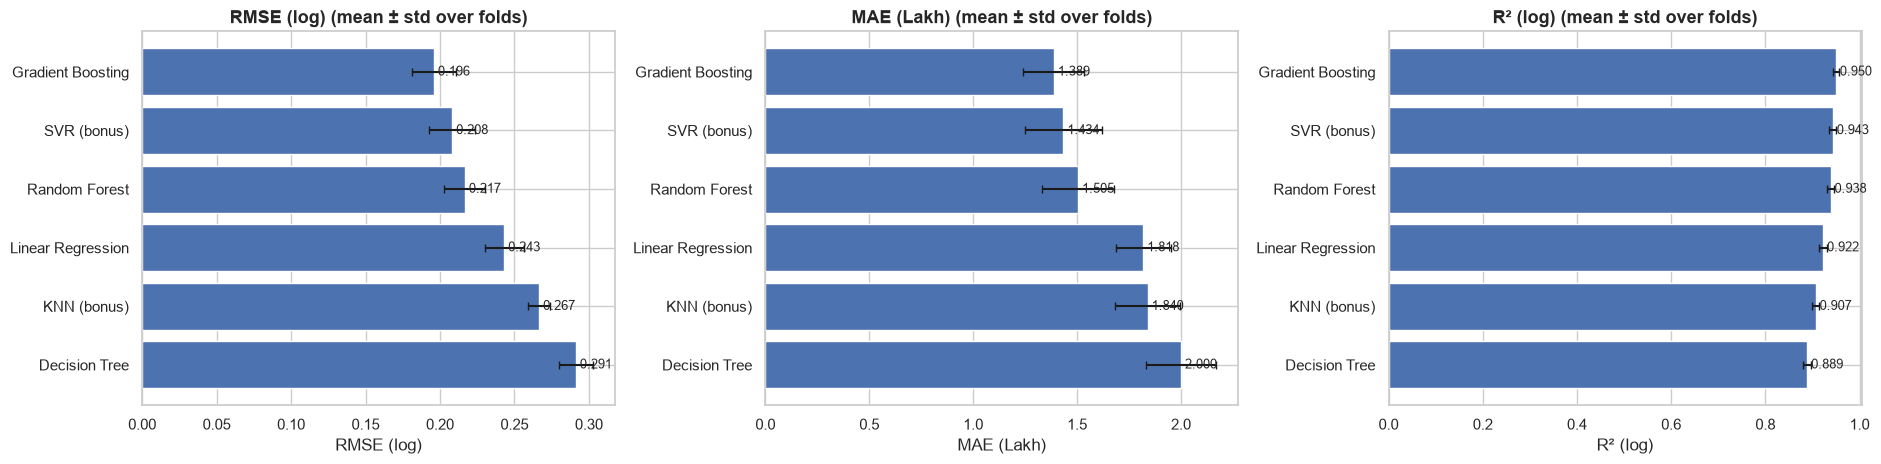

In [8]:
print("Standard deviation of each metric across the 5 folds:")
display(regression_summary_std.loc[regression_summary.sort_values("RMSE (log)").index])

figure, axes = plt.subplots(1, 3, figsize=(19, 4.8))
order = regression_summary.drop(index="Mean baseline").sort_values("RMSE (log)").index
for axis, metric in zip(axes, ["RMSE (log)", "MAE (Lakh)", "R² (log)"]):
    axis.barh(order, regression_summary.loc[order, metric], xerr=regression_summary_std.loc[order, metric],
              color=sns.color_palette("deep")[0], capsize=3)
    axis.invert_yaxis()
    for position, value in enumerate(regression_summary.loc[order, metric]):
        axis.text(value, position, f" {value:.3f}", va="center", fontsize=9)
    axis.set_title(f"{metric} (mean ± std over folds)")
    axis.set_xlabel(metric)
plt.tight_layout()
plt.show()

**Model comparison**
* **Every model beats the mean baseline by a wide margin** (baseline: RMSE(log) 0.874, R² ≈ 0, a median error of 55%), so the features carry real information about the price.
* **Gradient Boosting is the best model on every metric** except the median percentage error, where the SVR is marginally better: RMSE(log) 0.195, R²(log) 0.950, MAE 1.39 Lakh, a typical (median) error of about 10% of the price.
* SVR (0.208) and Random Forest (0.217) come next, then **Linear Regression (0.243)**, KNN (0.267) and the single **Decision Tree (0.291)**, which is the weakest model.
* The fold-to-fold standard deviation of RMSE(log) is ~0.015, so the gap between the three best models is of the order of one standard deviation, while the gap to the linear model and the single tree is clearly real.
* **Train vs validation error (bias–variance):** linear regression has almost no gap (0.240 vs 0.243) but a high error on both — **bias**. KNN is the opposite extreme: with distance weighting it reproduces the training cars exactly (train RMSE ≈ 0) and has the largest gap (0.264) — **variance**. Random Forest (gap 0.095), the single tree (0.073) and SVR (0.078) are in between, and Gradient Boosting has the **smallest gap of the flexible models (0.052)** together with the lowest validation error — the best balance.
* The **Lakh-scale metrics are much noisier** (the std of MSE across folds is ~45% of its mean for Gradient Boosting) because a handful of luxury cars in a given fold dominate squared errors measured in money. R² on the Lakh scale (0.90) is lower than on the log scale (0.95) for the same reason.

**Why a log target? — Linear regression on the raw price.**
Before analysing errors, it is worth showing what happens if the linear model is asked to predict the price in Lakh directly, as the most naive formulation would do:

Negative price predictions: 512 of 6,019 cars (8.5%)
MAE on raw price: 2.95 Lakh vs 1.82 Lakh with the log target


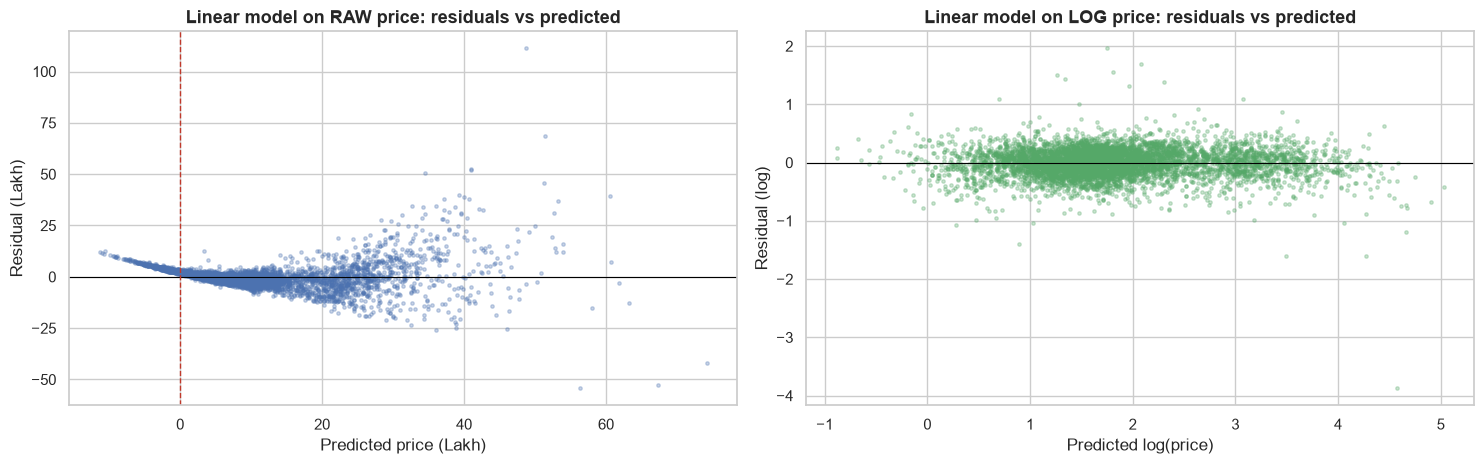

In [9]:
raw_linear_oof = pd.Series(np.nan, index=cars.index)
for train_index, valid_index in regression_folds.split(features):
    fitted = make_pipeline(LinearRegression()).fit(features.iloc[train_index], cars["Price"].iloc[train_index])
    raw_linear_oof.iloc[valid_index] = fitted.predict(features.iloc[valid_index])

print(f"Negative price predictions: {(raw_linear_oof < 0).sum()} of {len(cars):,} cars "
      f"({(raw_linear_oof < 0).mean():.1%})")
print(f"MAE on raw price: {mean_absolute_error(cars['Price'], raw_linear_oof):.2f} Lakh "
      f"vs {regression_summary.loc['Linear Regression', 'MAE (Lakh)']:.2f} Lakh with the log target")

figure, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].scatter(raw_linear_oof, cars["Price"] - raw_linear_oof, s=6, alpha=0.3)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].axvline(0, color="#c0392b", linestyle="--", linewidth=1)
axes[0].set_title("Linear model on RAW price: residuals vs predicted")
axes[0].set_xlabel("Predicted price (Lakh)"); axes[0].set_ylabel("Residual (Lakh)")
linear_log_residual = log_price - regression_oof["Linear Regression"]
axes[1].scatter(regression_oof["Linear Regression"], linear_log_residual, s=6, alpha=0.3, color=sns.color_palette("deep")[2])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Linear model on LOG price: residuals vs predicted")
axes[1].set_xlabel("Predicted log(price)"); axes[1].set_ylabel("Residual (log)")
plt.tight_layout()
plt.show()

Asking a linear model to predict the raw price produces **negative prices for 512 cars (8.5%)** and a clear **curved, funnel-shaped** residual pattern: the residuals are positive at both ends and negative in the middle (the relationship is not linear), and their spread grows with the prediction (heteroscedasticity). With the log target the same model has a MAE of 1.82 instead of 2.95 Lakh, and the residual cloud is flat and roughly even. This is a first example of an error caused by the **problem formulation**, not by the data or the algorithm.

## 4. Regression Error Analysis

The detailed error analysis is done for the **best model (Gradient Boosting)** and compared with the **Linear Regression baseline**, because the contrast between them is the most instructive. All errors are out-of-fold.

Two residual scales are used:
* **log residual** = log(y) − log(ŷ) — the scale the models are trained on; a residual of +0.10 means the car is ~10.5% *more expensive* than predicted.
* **Lakh residual** = y − ŷ — the business scale, required by the assignment definition *Residual = y − ŷ*.

In [10]:
BEST_REGRESSOR = regression_summary["RMSE (log)"].idxmin()
BASELINE_REGRESSOR = "Linear Regression"
print(f"Best model by RMSE (log): {BEST_REGRESSOR}")


def build_error_frame(model_name: str) -> pd.DataFrame:
    """Join out-of-fold predictions and errors to the car attributes for diagnosis."""
    frame = cars.copy()
    frame["Predicted_Log"] = regression_oof[model_name]
    frame["Predicted_Price"] = np.exp(frame["Predicted_Log"])
    frame["Residual_Log"] = frame["Log_Price"] - frame["Predicted_Log"]
    frame["Residual_Lakh"] = frame["Price"] - frame["Predicted_Price"]
    frame["Abs_Error_Lakh"] = frame["Residual_Lakh"].abs()
    frame["Abs_Error_Log"] = frame["Residual_Log"].abs()
    return frame


best_errors = build_error_frame(BEST_REGRESSOR)
baseline_errors = build_error_frame(BASELINE_REGRESSOR)

Best model by RMSE (log): Gradient Boosting


### 4.1 Residual Analysis

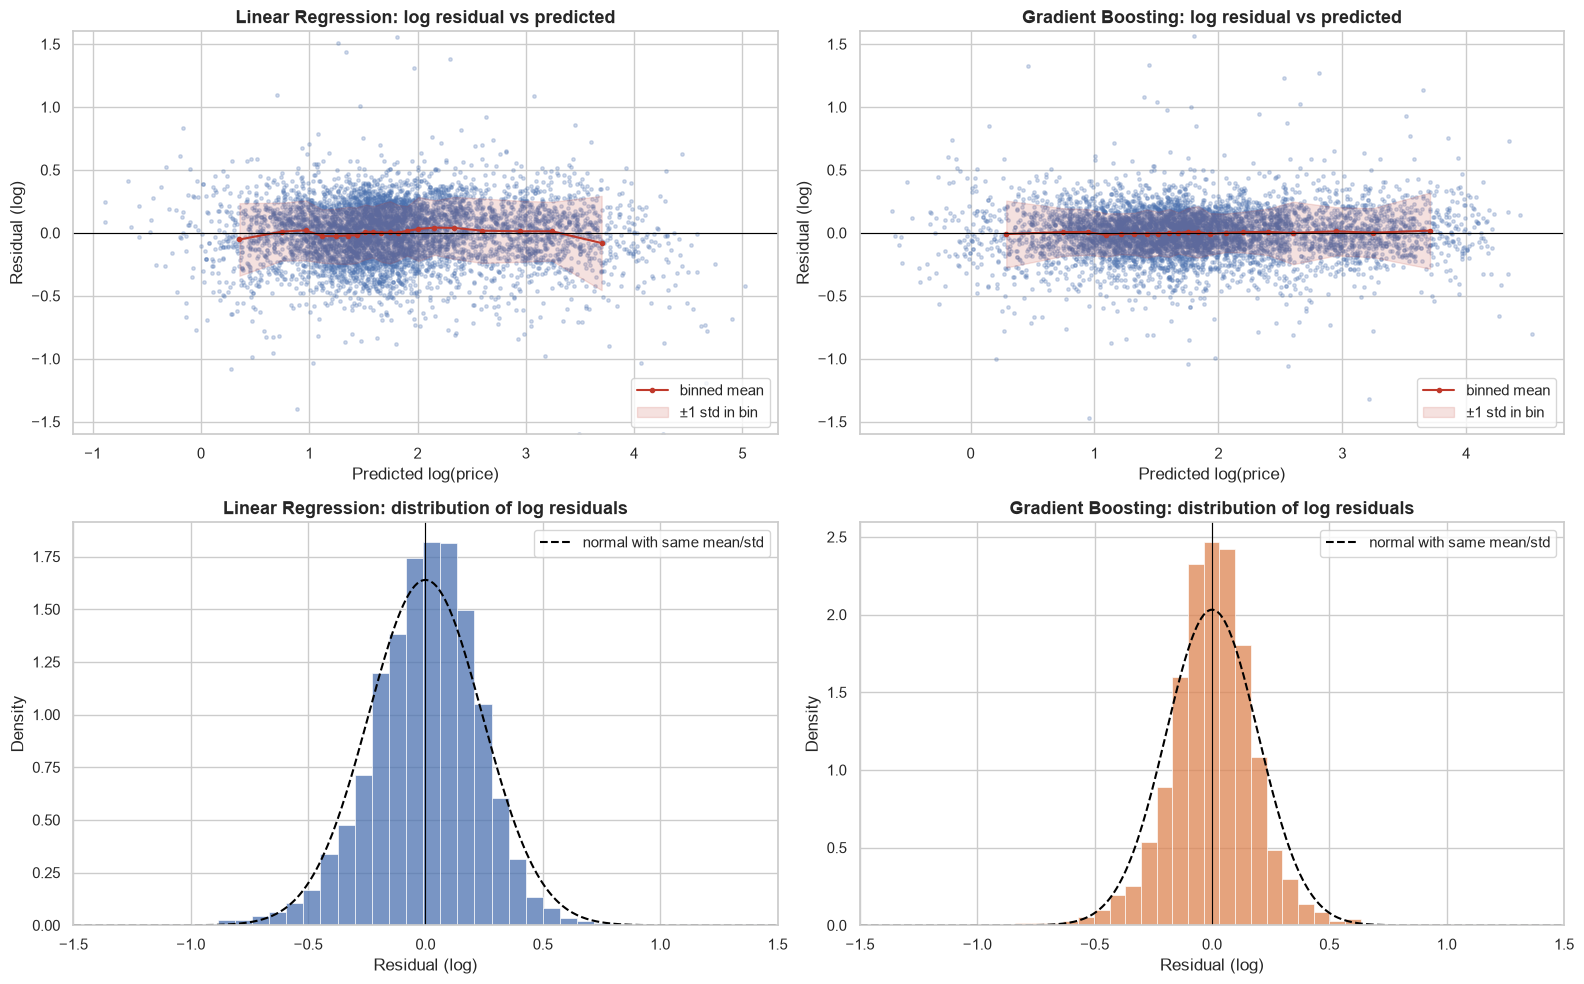

In [11]:
def binned_trend(x_values: pd.Series, y_values: pd.Series, n_bins: int = 20) -> pd.DataFrame:
    """Mean and std of y inside quantile bins of x — a simple, assumption-free trend line."""
    bins = pd.qcut(x_values, q=n_bins, duplicates="drop")
    grouped = y_values.groupby(bins, observed=True)
    return pd.DataFrame({"x": x_values.groupby(bins, observed=True).median(),
                         "mean": grouped.mean(), "std": grouped.std()})


figure, axes = plt.subplots(2, 2, figsize=(16, 10))
for column, (name, errors) in enumerate([(BASELINE_REGRESSOR, baseline_errors), (BEST_REGRESSOR, best_errors)]):
    axis = axes[0, column]
    axis.scatter(errors["Predicted_Log"], errors["Residual_Log"], s=6, alpha=0.25)
    trend = binned_trend(errors["Predicted_Log"], errors["Residual_Log"])
    axis.plot(trend["x"], trend["mean"], color="#c0392b", marker="o", markersize=3, label="binned mean")
    axis.fill_between(trend["x"], trend["mean"] - trend["std"], trend["mean"] + trend["std"],
                      color="#c0392b", alpha=0.15, label="±1 std in bin")
    axis.axhline(0, color="black", linewidth=0.8)
    axis.set_title(f"{name}: log residual vs predicted")
    axis.set_xlabel("Predicted log(price)"); axis.set_ylabel("Residual (log)"); axis.set_ylim(-1.6, 1.6)
    axis.legend(loc="lower right")

    axis = axes[1, column]
    sns.histplot(errors["Residual_Log"], bins=80, stat="density", ax=axis, color=sns.color_palette("deep")[column])
    grid = np.linspace(-1.5, 1.5, 300)
    axis.plot(grid, stats.norm.pdf(grid, errors["Residual_Log"].mean(), errors["Residual_Log"].std()),
              color="black", linestyle="--", label="normal with same mean/std")
    axis.axvline(0, color="black", linewidth=0.8)
    axis.set_xlim(-1.5, 1.5)
    axis.set_title(f"{name}: distribution of log residuals")
    axis.set_xlabel("Residual (log)"); axis.legend()
plt.tight_layout()
plt.show()

In [12]:
def breusch_pagan_test(residuals: pd.Series, predicted: pd.Series) -> tuple:
    """Breusch–Pagan style test: regress squared residuals on the prediction; LM = n·R² ~ chi²(1)."""
    squared = residuals ** 2
    r_squared = np.corrcoef(predicted, squared)[0, 1] ** 2
    lm_statistic = len(residuals) * r_squared
    return lm_statistic, stats.chi2.sf(lm_statistic, df=1)


centering_rows = []
for name, errors in [(BASELINE_REGRESSOR, baseline_errors), (BEST_REGRESSOR, best_errors)]:
    t_statistic, t_p_value = stats.ttest_1samp(errors["Residual_Log"], 0)
    bp_log, bp_log_p = breusch_pagan_test(errors["Residual_Log"], errors["Predicted_Log"])
    bp_lakh, bp_lakh_p = breusch_pagan_test(errors["Residual_Lakh"], errors["Predicted_Price"])
    centering_rows.append({
        "model": name,
        "mean log residual": errors["Residual_Log"].mean(),
        "median log residual": errors["Residual_Log"].median(),
        "t-test p (mean = 0)": t_p_value,
        "mean Lakh residual": errors["Residual_Lakh"].mean(),
        "median Lakh residual": errors["Residual_Lakh"].median(),
        "BP p-value (log scale)": bp_log_p,
        "BP p-value (Lakh scale)": bp_lakh_p,
    })
pd.DataFrame(centering_rows).set_index("model")

,mean log residual,median log residual,t-test p (mean = 0),mean Lakh residual,median Lakh residual,BP p-value (log scale),BP p-value (Lakh scale)
model,,,,,,,
Linear Regression,-0.000,0.011,0.980,0.134,0.048,0.000,0.000
Gradient Boosting,0.001,0.004,0.828,0.256,0.021,0.012,0.000


In [13]:
spread_by_prediction = best_errors.assign(
    predicted_quintile=pd.qcut(best_errors["Predicted_Price"], 5,
                               labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 most expensive"])
).groupby("predicted_quintile", observed=True).agg(
    cars=("Price", "size"),
    predicted_price_range=("Predicted_Price", lambda values: f"{values.min():.1f}–{values.max():.1f}"),
    std_residual_log=("Residual_Log", "std"),
    std_residual_lakh=("Residual_Lakh", "std"),
    MAE_lakh=("Abs_Error_Lakh", "mean"),
)
print(f"Heteroscedasticity check for {BEST_REGRESSOR}: spread of residuals by predicted-price quintile")
spread_by_prediction

Heteroscedasticity check for Gradient Boosting: spread of residuals by predicted-price quintile


,cars,predicted_price_range,std_residual_log,std_residual_lakh,MAE_lakh
predicted_quintile,,,,,
Q1 cheapest,1204,0.5–3.2,0.206,0.449,0.316
Q2,1204,3.2–4.7,0.174,0.798,0.510
Q3,1203,4.7–6.5,0.188,1.567,0.761
Q4,1204,6.5–12.1,0.167,1.544,1.114
Q5 most expensive,1204,12.1–92.8,0.239,7.606,4.241


#### Is there a *sector* that is more likely to have high errors?
We define sectors in three ways: **market segment** (brand tier), **fuel/gearbox**, and **city**. The error is measured as the absolute log residual (≈ relative error), so that expensive and cheap cars are compared fairly.

In [14]:
PREMIUM_BRANDS = {"Audi", "BMW", "Mercedes-Benz", "Jaguar", "Land Rover", "Porsche", "Volvo", "Mini",
                  "Lamborghini", "Bentley", "Jeep", "Mitsubishi", "Isuzu"}
brand_counts = cars["Brand"].value_counts()
RARE_BRAND_MAX_ROWS = 30


def market_segment(row: pd.Series) -> str:
    """Brand tier with a separate bucket for brands the model has very little data on."""
    if brand_counts[row["Brand"]] < RARE_BRAND_MAX_ROWS:
        return "Rare brand (<30 cars)"
    return "Premium brand" if row["Brand"] in PREMIUM_BRANDS else "Mass-market brand"


for frame in (best_errors, baseline_errors):
    frame["Segment"] = frame.apply(market_segment, axis=1)
    frame["Fuel_Gearbox"] = frame["Fuel_Type"].replace({"LPG": "CNG/LPG", "CNG": "CNG/LPG"}) + " / " + frame["Transmission"]

HIGH_ERROR_LOG = np.log(1.25)      # 'high error' = more than 25% away from the true price


def sector_error_table(errors: pd.DataFrame, sector_column: str) -> pd.DataFrame:
    """Relative error summary per sector, sorted by the share of large errors."""
    table = errors.groupby(sector_column).agg(
        cars=("Price", "size"),
        median_abs_error_pct=("Abs_Error_Log", lambda values: (np.exp(values.median()) - 1) * 100),
        high_error_share_pct=("Abs_Error_Log", lambda values: (values > HIGH_ERROR_LOG).mean() * 100),
        mean_log_residual=("Residual_Log", "mean"),
        MAE_lakh=("Abs_Error_Lakh", "mean"),
    )
    return table[table["cars"] >= 10].sort_values("high_error_share_pct", ascending=False)


for sector in ["Segment", "Fuel_Gearbox", "Location"]:
    print(f"\n=== {BEST_REGRESSOR}: errors by {sector} (share of cars with >25% error) ===")
    display(sector_error_table(best_errors, sector).round(2))


=== Gradient Boosting: errors by Segment (share of cars with >25% error) ===


,cars,median_abs_error_pct,high_error_share_pct,mean_log_residual,MAE_lakh
Segment,,,,,
Rare brand (<30 cars),158,15.630,34.180,0.020,4.610
Premium brand,921,13.020,23.340,0.020,4.390
Mass-market brand,4940,10.590,15.550,-0.000,0.730



=== Gradient Boosting: errors by Fuel_Gearbox (share of cars with >25% error) ===


,cars,median_abs_error_pct,high_error_share_pct,mean_log_residual,MAE_lakh
Fuel_Gearbox,,,,,
Diesel / Automatic,1108,12.110,21.300,-0.010,3.610
CNG/LPG / Manual,66,11.450,19.700,0.000,0.450
Petrol / Automatic,610,11.120,19.340,-0.000,2.450
Diesel / Manual,2097,11.000,16.550,0.010,0.820
Petrol / Manual,2136,10.390,15.030,-0.000,0.520



=== Gradient Boosting: errors by Location (share of cars with >25% error) ===


,cars,median_abs_error_pct,high_error_share_pct,mean_log_residual,MAE_lakh
Location,,,,,
Chennai,494,12.450,22.270,0.010,1.120
Jaipur,413,11.160,20.580,-0.010,0.830
Kolkata,535,11.190,20.560,-0.010,0.950
Pune,622,12.450,19.770,-0.010,1.020
Mumbai,790,11.290,18.480,-0.000,1.550
Ahmedabad,224,11.150,17.860,0.010,1.300
Bangalore,358,10.430,16.760,0.010,1.860
Hyderabad,742,11.120,16.710,0.010,1.470
Delhi,554,9.400,14.260,-0.010,1.500


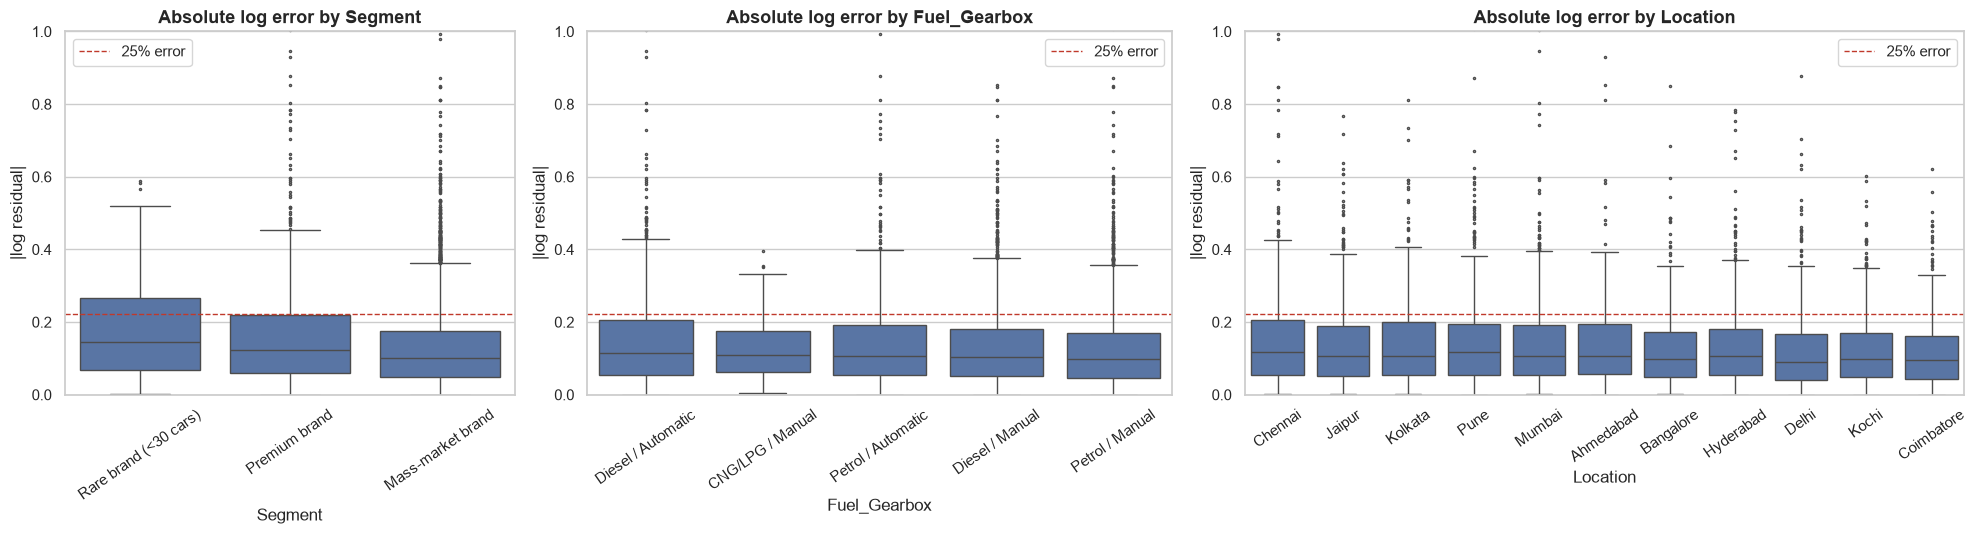

In [15]:
figure, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1, 1.3, 1.6]})
for axis, sector in zip(axes, ["Segment", "Fuel_Gearbox", "Location"]):
    order = sector_error_table(best_errors, sector).index
    plot_data = best_errors[best_errors[sector].isin(order)]
    sns.boxplot(data=plot_data, x=sector, y="Abs_Error_Log", order=order, ax=axis, fliersize=1.5,
                color=sns.color_palette("deep")[0])
    axis.axhline(HIGH_ERROR_LOG, color="#c0392b", linestyle="--", linewidth=1, label="25% error")
    axis.set_ylim(0, 1.0)
    axis.set_title(f"Absolute log error by {sector}")
    axis.set_xlabel(sector); axis.set_ylabel("|log residual|")
    axis.tick_params(axis="x", rotation=35)
    axis.legend()
plt.tight_layout()
plt.show()

**Are the residuals centred around zero?**
* **On the log scale, yes.** The mean log residual is 0.000 for both models (t-test p ≈ 0.98–0.99) and the median is very close to zero (+0.011 for linear regression, +0.004 for Gradient Boosting). Cross-validated models are unbiased *on average*.
* **On the Lakh scale, not quite.** The mean residual is positive (+0.13 Lakh for linear regression, +0.25 Lakh for Gradient Boosting): the models under-predict the average price in money. Two effects explain this: exp(mean of log) is the *geometric* mean, which is always below the arithmetic mean (a known *re-transformation bias*), and the most expensive cars are under-predicted (see below).

**Systematic patterns?**
* For **linear regression** the binned mean of the residuals is slightly curved: negative for the cheapest and most expensive predictions and positive in the middle — a leftover non-linearity the linear model cannot express.
* For **Gradient Boosting** the binned mean is flat across the whole range of predictions — the non-linearity has been captured.
* Both models show **regression towards the mean** when the residuals are grouped by the *true* price (Section 4.2): cheap cars are over-predicted and expensive cars are under-predicted.

**Heteroscedasticity?**
* **Lakh scale: strong.** The standard deviation of the residuals rises from 0.43 Lakh for the cheapest fifth of cars to 7.47 Lakh for the most expensive fifth, and the Breusch–Pagan test rejects constant variance (p < 0.001). This is expected: an error of 10% is 0.3 Lakh on a 3-Lakh car and 5 Lakh on a 50-Lakh car.
* **Log scale: mild.** The spread is almost constant (std 0.17–0.20) in the middle of the range and larger only at the two extremes (0.20 for the cheapest, 0.24 for the most expensive cars). The test still detects this for linear regression (p < 0.001) and weakly for Gradient Boosting (p = 0.014). The log transform removed most, but not all, of the heteroscedasticity — the extremes of the market remain harder to price.

**Sectors with high error rates**
* **Market segment is the clearest one.** More than a third (36%) of the cars from **rare brands** (< 30 cars each: Porsche, Bentley, Lamborghini, Fiat, Datsun…) are mispriced by more than 25%, against 24% for premium brands and only 15.5% for mass-market brands. In money, premium-brand errors are six times larger (MAE 4.4 vs 0.72 Lakh).
  *Why?* (1) **Too little data**: with 1–30 examples per brand, the model cannot learn the brand's price level, and the "infrequent" one-hot level lumps a Lamborghini together with a Datsun. (2) **Missing information**: premium prices depend on the exact variant, options and condition, which the listing does not contain. (3) Luxury cars are a **heterogeneous** group (a 5-year-old BMW 3-series and a 2-year-old Range Rover differ by a factor of 5).
* **Automatic diesel cars** (mostly premium SUVs and sedans) have more large errors (22%) than manual petrol cars (15%), for the same reason. The small **CNG/LPG** group also has a high rate (23%) — only 66 cars.
* **City** matters less, but the pattern is interesting: Chennai (22%), Kolkata and Jaipur (20%) are hardest, while Coimbatore (12%) and Kochi (13%) are easiest. Assignment 1 showed that Coimbatore and Kochi list the *youngest* cars and Chennai the *oldest*; older cars are harder to price (Section 4.2), so the "city effect" is largely an **age-mix effect**.

### 4.2 Error as a Function of Features
For each numerical feature we plot the (log) residual — which reveals **bias** (systematic over/under-prediction) — and the absolute error — which reveals **where the model is uncertain**. The red line is the mean inside 20 quantile bins of the feature.

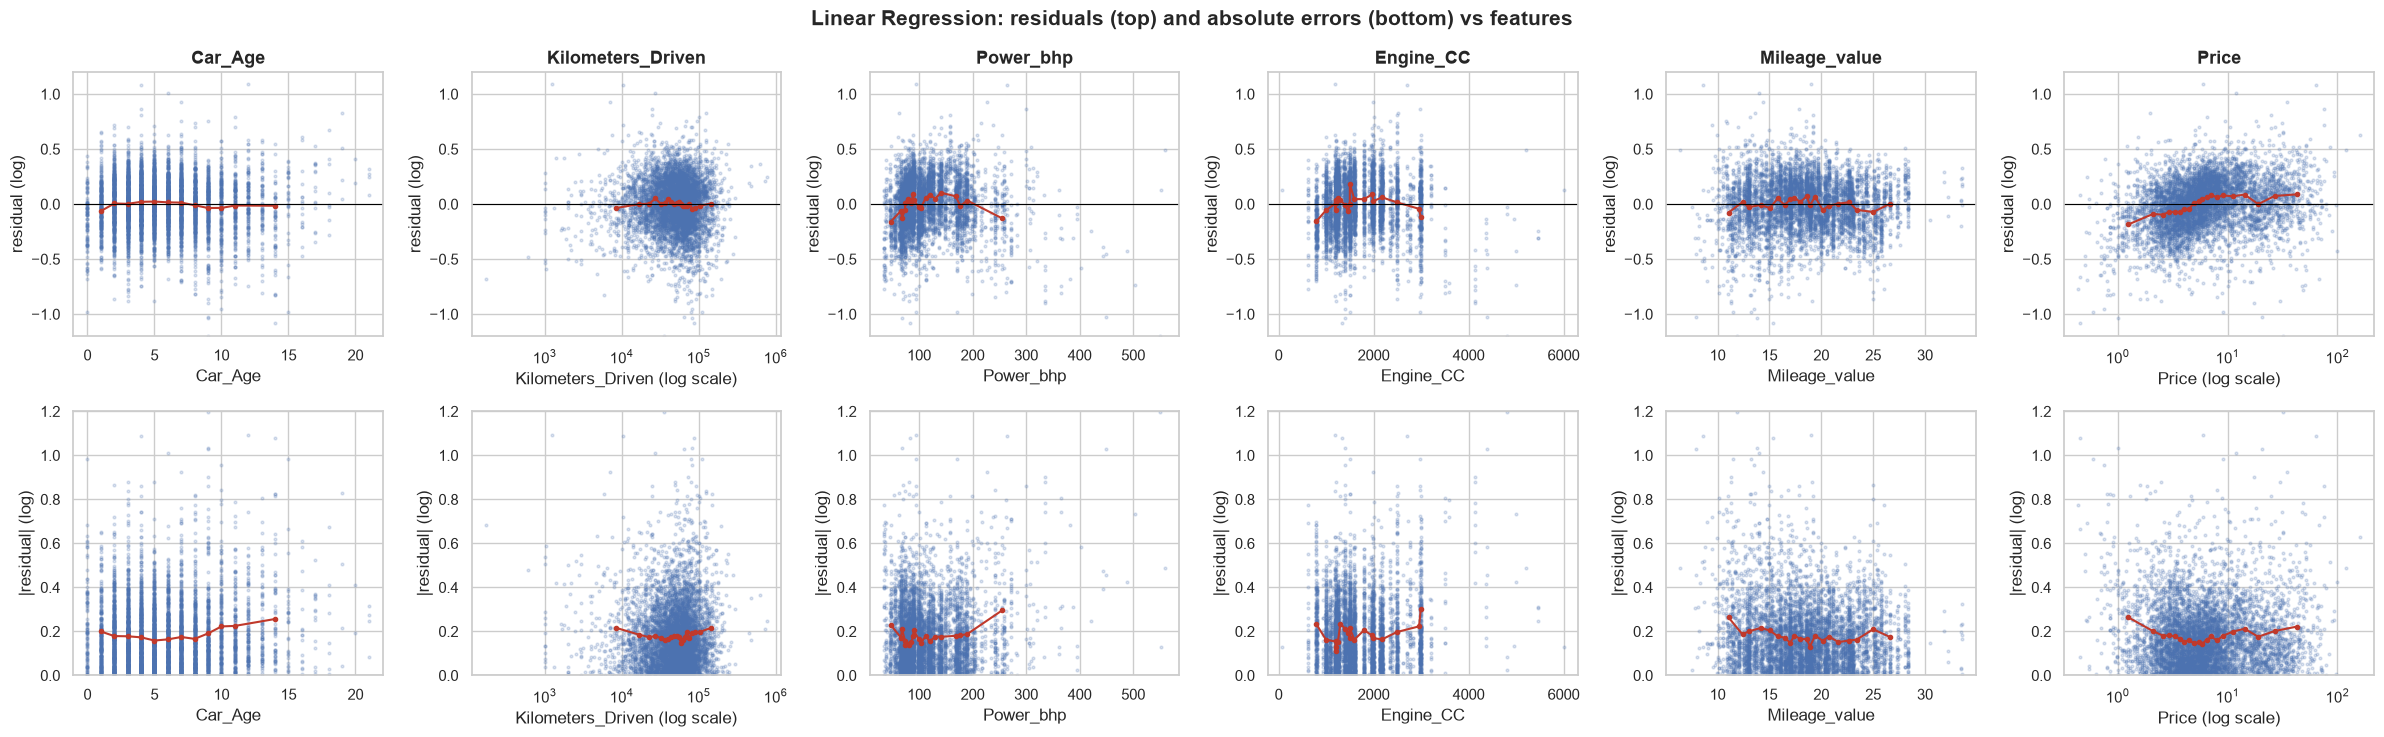

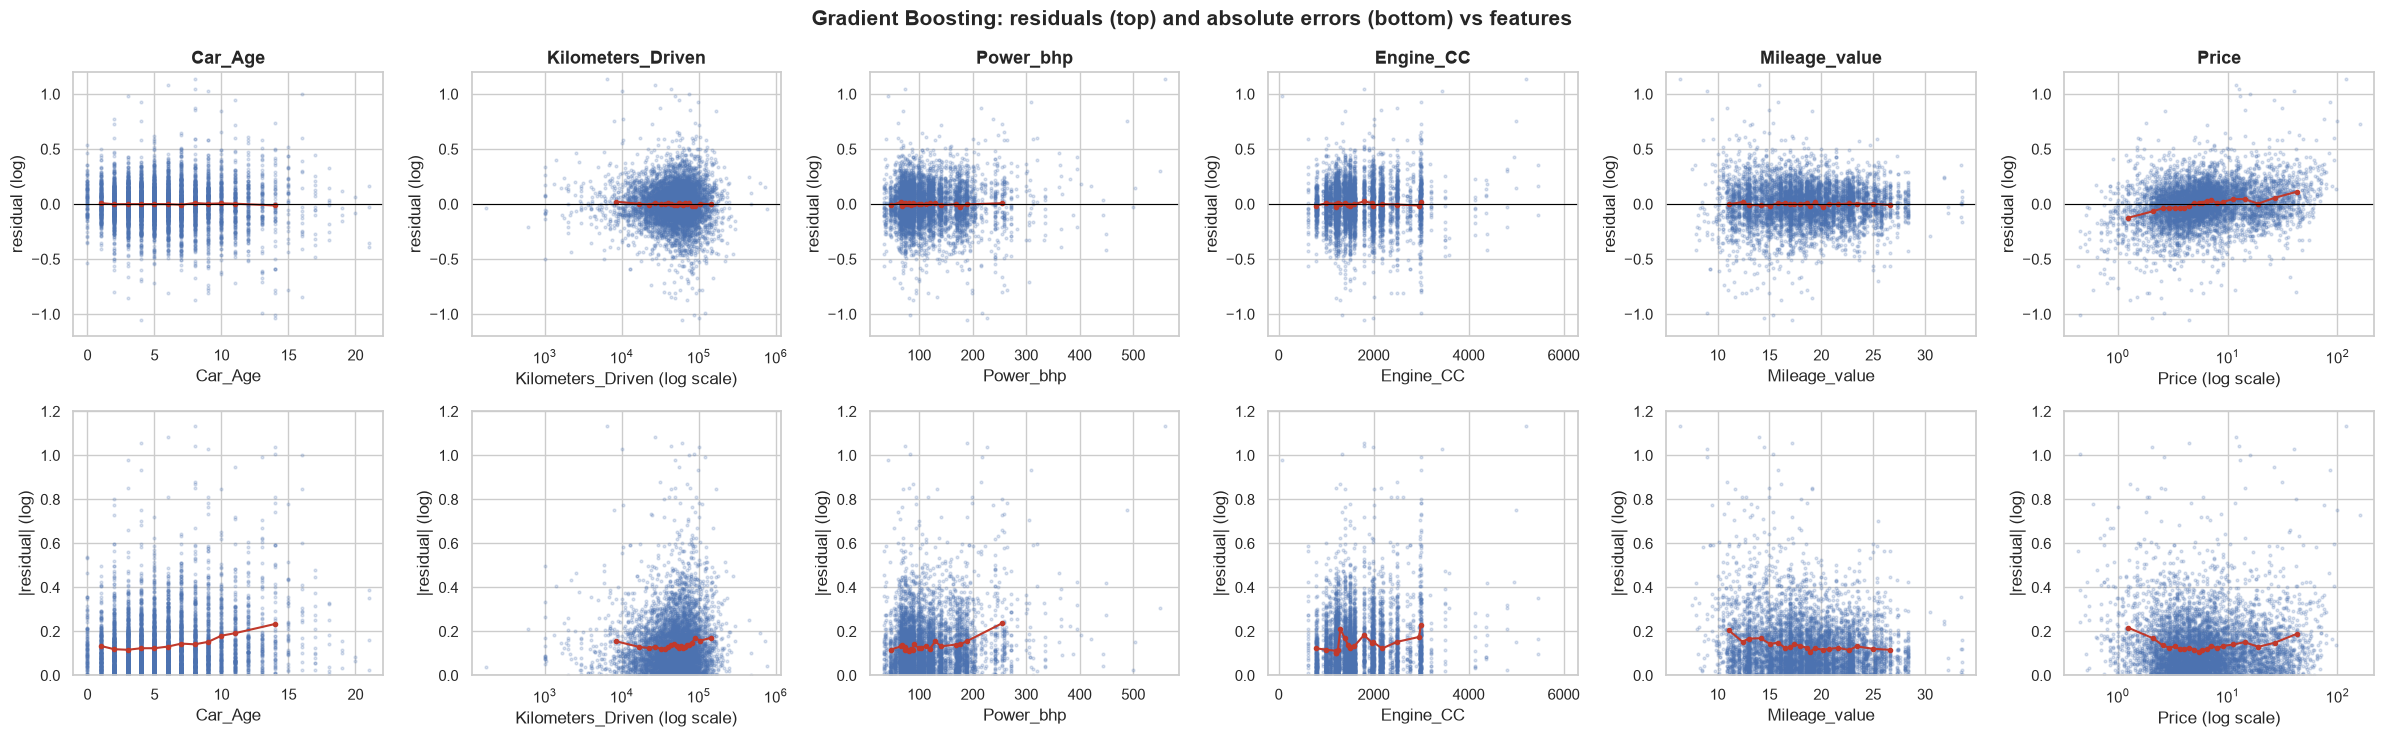

In [16]:
DIAGNOSTIC_FEATURES = ["Car_Age", "Kilometers_Driven", "Power_bhp", "Engine_CC", "Mileage_value", "Price"]
for name, errors in [(BASELINE_REGRESSOR, baseline_errors), (BEST_REGRESSOR, best_errors)]:
    figure, axes = plt.subplots(2, len(DIAGNOSTIC_FEATURES), figsize=(24, 7.5))
    for column, feature in enumerate(DIAGNOSTIC_FEATURES):
        valid = errors[[feature, "Residual_Log", "Abs_Error_Log"]].dropna()
        log_axis = feature in ("Kilometers_Driven", "Price")
        for row, error_column in enumerate(["Residual_Log", "Abs_Error_Log"]):
            axis = axes[row, column]
            axis.scatter(valid[feature], valid[error_column], s=4, alpha=0.2)
            trend = binned_trend(valid[feature], valid[error_column])
            axis.plot(trend["x"], trend["mean"], color="#c0392b", marker="o", markersize=3)
            axis.axhline(0, color="black", linewidth=0.8)
            if log_axis:
                axis.set_xscale("log")
            axis.set_ylim((-1.2, 1.2) if row == 0 else (0, 1.2))
            axis.set_xlabel(feature + (" (log scale)" if log_axis else ""))
            axis.set_ylabel("residual (log)" if row == 0 else "|residual| (log)")
            if row == 0:
                axis.set_title(feature)
    figure.suptitle(f"{name}: residuals (top) and absolute errors (bottom) vs features", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [17]:
def bias_by_feature_bins(errors: pd.DataFrame, feature: str, n_bins: int = 5) -> pd.Series:
    """Mean log residual per quantile bin of a feature (positive = model under-predicts)."""
    bins = pd.qcut(errors[feature], q=n_bins, duplicates="drop")
    return errors.groupby(bins, observed=True)["Residual_Log"].mean()


print("Mean log residual by quintile of the TRUE price (regression-to-the-mean check):")
display(pd.DataFrame({name: bias_by_feature_bins(errors, "Price")
                      for name, errors in [(BASELINE_REGRESSOR, baseline_errors), (BEST_REGRESSOR, best_errors)]}))
print("Mean log residual by quintile of Car_Age:")
display(pd.DataFrame({name: bias_by_feature_bins(errors, "Car_Age")
                      for name, errors in [(BASELINE_REGRESSOR, baseline_errors), (BEST_REGRESSOR, best_errors)]}))

Mean log residual by quintile of the TRUE price (regression-to-the-mean check):


,Linear Regression,Gradient Boosting
Price,,
"(0.439, 3.1]",-0.111,-0.065
"(3.1, 4.7]",-0.058,-0.030
"(4.7, 6.75]",0.036,0.016
"(6.75, 12.5]",0.073,0.028
"(12.5, 160.0]",0.062,0.055


Mean log residual by quintile of Car_Age:


,Linear Regression,Gradient Boosting
Car_Age,,
"(-0.001, 3.0]",-0.012,0.001
"(3.0, 4.0]",0.020,-0.000
"(4.0, 6.0]",0.020,-0.000
"(6.0, 8.0]",0.003,0.001
"(8.0, 21.0]",-0.025,0.001


In [18]:
def feature_error_summary(errors: pd.DataFrame, feature_columns: list) -> pd.DataFrame:
    """How strongly each feature is associated with the SIZE of the error and with its DIRECTION."""
    rows = {}
    for feature in feature_columns:
        valid = errors[[feature, "Residual_Log", "Abs_Error_Log"]].dropna()
        deciles = pd.qcut(valid[feature].rank(method="first"), 10, labels=False)
        decile_error = valid.groupby(deciles)["Abs_Error_Log"].mean()
        decile_bias = valid.groupby(deciles)["Residual_Log"].mean()
        rows[feature] = {"Spearman(feature, |error|)": stats.spearmanr(valid[feature], valid["Abs_Error_Log"])[0],
                         "worst / best decile |error|": decile_error.max() / decile_error.min(),
                         "range of mean residual across deciles": decile_bias.max() - decile_bias.min()}
    return pd.DataFrame(rows).T


print(f"{BEST_REGRESSOR}: association of each feature with the error (all out-of-fold rows)")
feature_error_summary(best_errors, DIAGNOSTIC_FEATURES).sort_values("worst / best decile |error|", ascending=False)

Gradient Boosting: association of each feature with the error (all out-of-fold rows)


,"Spearman(feature, |error|)",worst / best decile |error|,range of mean residual across deciles
Engine_CC,0.114,1.821,0.019
Car_Age,0.122,1.749,0.018
Price,-0.004,1.726,0.180
Power_bhp,0.089,1.713,0.018
Mileage_value,-0.100,1.541,0.016
Kilometers_Driven,0.065,1.348,0.029


**Findings — error vs features**
* The summary table separates the two questions. **Engine size, car age and power** are most associated with the *size* of the error (the worst decile has 1.7–1.8× the error of the best decile), while their *bias* is negligible (mean residual varies by < 0.02 across deciles). **The true price is the opposite**: almost no relation to the error size (Spearman ≈ 0) but by far the largest *bias* (0.18 range across deciles) — it decides the *direction* of the error.
* **True price (right-most panels): the strongest pattern.** The residual rises steadily with the true price: cheap cars are over-predicted (−0.066 in log for the cheapest fifth ≈ 6% too high) and expensive cars under-predicted (+0.055 ≈ 6% too low). For linear regression the effect is twice as large (−0.111 / +0.073). This is **regression to the mean**: when the features do not fully explain why a car is unusually cheap or expensive, the model pulls the prediction towards the average. It is also a sign of **missing features** (condition, trim level, accident history).
* **Car age:** Gradient Boosting has **no bias** by age (mean residual ≈ 0 in every age group), while linear regression has a small wave (±0.02) — the depreciation curve is not exactly linear in log-price. The **absolute error grows for cars older than ~10 years** in both models: old cars are rare, and their price depends more on condition than on specifications.
* **Power / Engine size:** the absolute error increases above ~200 bhp / 3,000 CC — the luxury sub-population again. Linear regression shows a clear **non-linear bias** in power (positive residual in the middle, negative at the top): the price does not grow proportionally with power at the high end.
* **Kilometers driven:** almost no bias, and the error is only slightly larger at both ends — very low km (< 10,000: mean |log error| 0.16) and very high km (> 100,000: 0.16) vs 0.13 in the middle. This is consistent with Assignment 1, where km was a weak price factor and odometer values were self-reported and rounded.
* **Fuel efficiency:** errors are larger at low values (< 12 kmpl), which again identifies large-engine luxury cars.
* **Hidden sub-populations** found: (1) the luxury segment, (2) very old cars, (3) near-new cars with very low mileage. Each behaves differently from the mass market that dominates the training data.

### 4.3 Analysis of Extreme Errors (top 5%)
The top 5% of cars by **absolute error in Lakh** (as defined in the assignment) are examined. Each is automatically tagged with possible causes that can be checked in the data:

| Tag | Rule | Type of cause |
|---|---|---|
| `odometer anomaly` | raw km > 300,000, < 1,000, or the impossible 6.5M value | data quality |
| `missing specs` | Power / Engine / Mileage was missing and had to be imputed | data quality |
| `duplicate listing` | the same car (name, city, year, km) appears more than once | data quality |
| `price above new price` | used price > listed new price | data quality |
| `implausible price` | premium brand, ≤ 3 years old, but priced under 8 Lakh (e.g. a 2019 Porsche Cayenne at 2 Lakh) | data quality (likely typo) |
| `rare brand` / `rare model` | brand with < 30 cars / model with < 5 cars in the data | rare case |
| `luxury (>40 Lakh)` | true price above 40 Lakh — only ~3% of cars | rare case / model limitation |
| *(none)* | nothing unusual found in the data | model limitation (missing information) |

In [19]:
model_counts = cars["Model"].value_counts()
duplicate_keys = all_cars.duplicated(subset=["Name", "Location", "Year", "Raw_Kilometers"], keep=False)


def tag_error_causes(row: pd.Series) -> list:
    """Return the list of data-quality / rarity flags that may explain a large error."""
    tags = []
    if row["Raw_Kilometers"] > 300_000 or row["Raw_Kilometers"] < 1_000:
        tags.append("odometer anomaly")
    if pd.isna(row["Power_bhp"]) or pd.isna(row["Engine_CC"]) or pd.isna(row["Mileage_value"]):
        tags.append("missing specs")
    if duplicate_keys.loc[row.name]:
        tags.append("duplicate listing")
    if pd.notna(row["New_Price_Lakh"]) and row["Price"] > row["New_Price_Lakh"]:
        tags.append("price above new price")
    if row["Brand"] in PREMIUM_BRANDS and row["Car_Age"] <= 3 and row["Price"] < 8:
        tags.append("implausible price")
    if brand_counts[row["Brand"]] < RARE_BRAND_MAX_ROWS:
        tags.append("rare brand")
    if model_counts[row["Model"]] < 5:
        tags.append("rare model")
    if row["Price"] > 40:
        tags.append("luxury (>40 Lakh)")
    return tags


def cause_category(tags: list) -> str:
    """Group the flags into the three causes asked for in the assignment."""
    if any(tag in tags for tag in ["odometer anomaly", "missing specs", "duplicate listing", "price above new price", "implausible price"]):
        return "Data quality issue"
    if any(tag in tags for tag in ["rare brand", "rare model", "luxury (>40 Lakh)"]):
        return "Rare / exceptional case"
    return "Model limitation"


def analyse_extreme_errors(errors: pd.DataFrame, error_column: str) -> pd.DataFrame:
    """Top-5% largest errors with their automatic cause tags."""
    cutoff = errors[error_column].quantile(1 - TOP_ERROR_SHARE)
    extreme = errors[errors[error_column] >= cutoff].copy()
    extreme["Tags"] = extreme.apply(tag_error_causes, axis=1)
    extreme["Cause"] = extreme["Tags"].apply(cause_category)
    return extreme.sort_values(error_column, ascending=False)


extreme_errors = analyse_extreme_errors(best_errors, "Abs_Error_Lakh")
all_tags = best_errors.apply(tag_error_causes, axis=1).apply(cause_category)
print(f"Top 5% = {len(extreme_errors)} cars with absolute error ≥ "
      f"{extreme_errors['Abs_Error_Lakh'].min():.2f} Lakh ({BEST_REGRESSOR})\n")

cause_comparison = pd.DataFrame({
    "top 5% errors (%)": extreme_errors["Cause"].value_counts(normalize=True) * 100,
    "all cars (%)": all_tags.value_counts(normalize=True) * 100,
}).round(1)
cause_comparison["over-representation"] = (cause_comparison["top 5% errors (%)"] / cause_comparison["all cars (%)"]).round(2)
display(cause_comparison)

print("Individual tags among the top 5% errors:")
display(extreme_errors["Tags"].explode().value_counts().to_frame("cars"))

Top 5% = 301 cars with absolute error ≥ 5.24 Lakh (Gradient Boosting)



,top 5% errors (%),all cars (%),over-representation
Data quality issue,9.000,3.900,2.310
Model limitation,44.200,89.400,0.490
Rare / exceptional case,46.800,6.700,6.990


Individual tags among the top 5% errors:


,cars
Tags,
luxury (>40 Lakh),117
rare model,40
rare brand,31
missing specs,22
implausible price,2
duplicate listing,2
odometer anomaly,1


In [20]:
EXTREME_COLUMNS = ["Name", "Location", "Year", "Raw_Kilometers", "Power_bhp", "Price", "Predicted_Price",
                   "Residual_Lakh", "Residual_Log", "Tags", "Cause"]
print("The 15 largest absolute errors:")
display(extreme_errors[EXTREME_COLUMNS].head(15))

extreme_relative = analyse_extreme_errors(best_errors, "Abs_Error_Log")
print(f"\nFor comparison — the top 5% by RELATIVE (log) error: median true price "
      f"{extreme_relative['Price'].median():.2f} Lakh vs {extreme_errors['Price'].median():.2f} Lakh for the top 5% by absolute error")
display(extreme_relative["Cause"].value_counts(normalize=True).mul(100).round(1).to_frame("% of top 5% relative errors"))
display(extreme_relative[EXTREME_COLUMNS].head(10))

The 15 largest absolute errors:


,Name,Location,Year,Raw_Kilometers,Power_bhp,Price,Predicted_Price,Residual_Lakh,Residual_Log,Tags,Cause
S.No.,,,,,,,,,,,
4079,Land Rover Range Rover 3.0 Diesel LWB Vogue,Hyderabad,2017,25000,255.000,160.000,77.201,82.799,0.729,[luxury (>40 Lakh)],Rare / exceptional case
5781,Lamborghini Gallardo Coupe,Delhi,2011,6500,560.000,120.000,38.625,81.375,1.134,"[rare brand, rare model, luxury (>40 Lakh)]",Rare / exceptional case
3132,Porsche Cayenne Base,Kochi,2019,14298,340.000,2.020,67.714,-65.694,-3.512,"[implausible price, rare brand]",Data quality issue
5919,Jaguar F Type 5.0 V8 S,Hyderabad,2015,8000,488.100,100.000,47.089,52.911,0.753,"[rare model, luxury (>40 Lakh)]",Rare / exceptional case
5535,BMW X6 xDrive 40d M Sport,Ahmedabad,2015,97003,308.430,85.000,33.501,51.499,0.931,[luxury (>40 Lakh)],Rare / exceptional case
2178,Land Rover Discovery HSE Luxury 3.0 TD6,Mumbai,2017,35000,255.000,41.600,92.830,-51.230,-0.803,[luxury (>40 Lakh)],Rare / exceptional case
5521,Bentley Continental Flying Spur,Hyderabad,2006,48000,552.000,59.000,16.620,42.380,1.267,"[rare brand, rare model, luxury (>40 Lakh)]",Rare / exceptional case
1984,BMW 7 Series 740Li,Bangalore,2017,17465,320.000,93.000,51.228,41.772,0.596,[luxury (>40 Lakh)],Rare / exceptional case
655,Jaguar XJ 2.0L Portfolio,Mumbai,2017,10501,237.400,75.000,34.634,40.366,0.773,[luxury (>40 Lakh)],Rare / exceptional case



For comparison — the top 5% by RELATIVE (log) error: median true price 4.85 Lakh vs 34.50 Lakh for the top 5% by absolute error


,% of top 5% relative errors
Cause,
Model limitation,70.800
Rare / exceptional case,16.300
Data quality issue,13.000


,Name,Location,Year,Raw_Kilometers,Power_bhp,Price,Predicted_Price,Residual_Lakh,Residual_Log,Tags,Cause
S.No.,,,,,,,,,,,
3132,Porsche Cayenne Base,Kochi,2019,14298,340.000,2.020,67.714,-65.694,-3.512,"[implausible price, rare brand]",Data quality issue
1460,Land Rover Range Rover Sport 2005 2012 Sport,Coimbatore,2008,69078,NaN,40.880,6.508,34.372,1.838,"[missing specs, luxury (>40 Lakh)]",Data quality issue
5075,Mercedes-Benz New C-Class C 200 Kompressor Ele...,Kolkata,2007,43627,186.000,29.000,6.091,22.909,1.561,[],Model limitation
5990,Tata New Safari DICOR 2.2 VX 4x2,Pune,2008,86000,138.000,0.600,2.606,-2.006,-1.469,[],Model limitation
1309,Volkswagen Beetle 2.0,Mumbai,2009,27078,114.400,15.950,4.208,11.742,1.332,[rare model],Rare / exceptional case
2119,Ford Freestyle Titanium Petrol,Mumbai,2007,1261,94.680,6.000,1.592,4.408,1.326,[rare model],Rare / exceptional case
3059,BMW 3 Series 320d Luxury Line,Delhi,2019,87000,190.000,6.670,24.991,-18.321,-1.321,[implausible price],Data quality issue
5521,Bentley Continental Flying Spur,Hyderabad,2006,48000,552.000,59.000,16.620,42.380,1.267,"[rare brand, rare model, luxury (>40 Lakh)]",Rare / exceptional case
2305,Porsche Cayman 2009-2012 S tiptronic,Mumbai,2011,8000,NaN,43.000,12.563,30.437,1.230,"[missing specs, rare brand, rare model, luxury...",Data quality issue


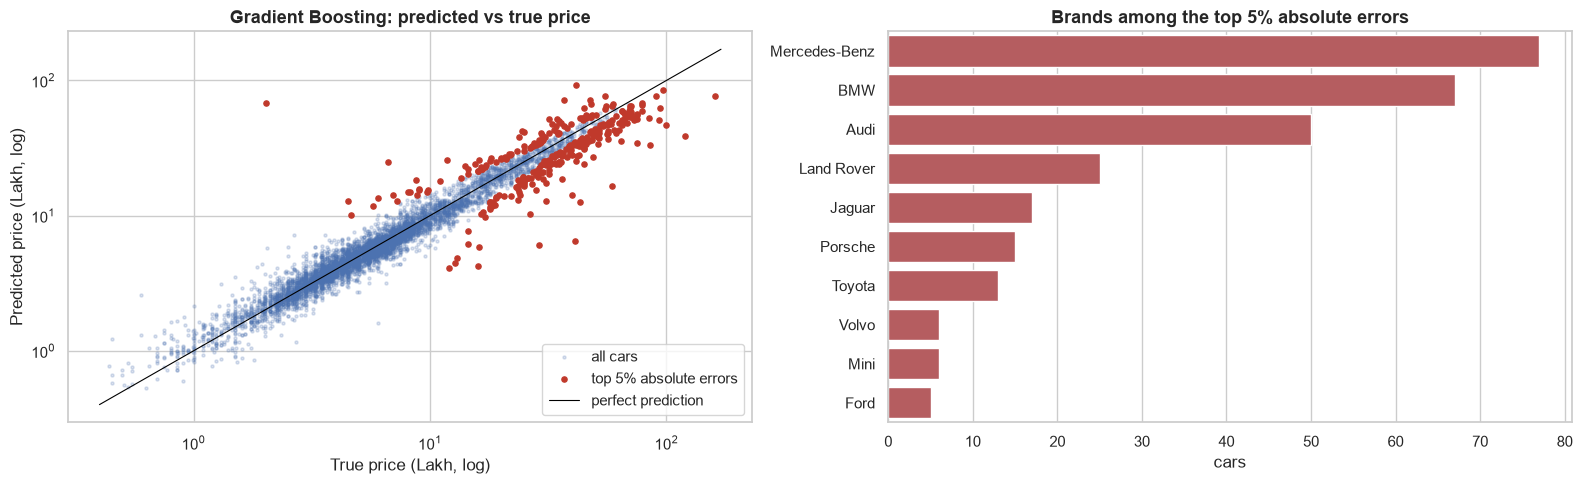

In [21]:
figure, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].scatter(best_errors["Price"], best_errors["Predicted_Price"], s=5, alpha=0.2, label="all cars")
axes[0].scatter(extreme_errors["Price"], extreme_errors["Predicted_Price"], s=14, color="#c0392b",
                label="top 5% absolute errors")
limits = [0.4, 170]
axes[0].plot(limits, limits, color="black", linewidth=0.8, label="perfect prediction")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title(f"{BEST_REGRESSOR}: predicted vs true price")
axes[0].set_xlabel("True price (Lakh, log)"); axes[0].set_ylabel("Predicted price (Lakh, log)"); axes[0].legend()

sns.countplot(data=extreme_errors, y="Brand", order=extreme_errors["Brand"].value_counts().head(10).index,
              ax=axes[1], color=sns.color_palette("deep")[3])
axes[1].set_title("Brands among the top 5% absolute errors")
axes[1].set_xlabel("cars"); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Discussion — where do the extreme errors come from?**
* **By absolute error (Lakh), the top 5% are the luxury market.** 301 cars with errors ≥ 5.18 Lakh; Mercedes-Benz, BMW, Audi, Land Rover, Jaguar and Porsche make up most of them. **Rare or exceptional cases** make up 46% of this group but only 7% of the data (6.8× over-represented), and **data-quality issues** are 2.4× over-represented (9% vs 4%). The remaining 45% have nothing unusual in the data — **model limitations**, mainly the under-prediction of expensive cars (red points below the diagonal in the scatter plot).
* **Individual cases:**
  * *Range Rover LWB Vogue 2017 — 160 Lakh, predicted 76.* The most expensive car in the data; nothing similar exists in the training folds, and a tree-based model **cannot extrapolate** beyond the prices it has seen. → rare case / model limitation.
  * *Lamborghini Gallardo, Bentley Continental* — a single example of the brand. → rare case.
  * *Porsche Cayenne 2019 — 2.02 Lakh, predicted 68.* A new Cayenne cannot cost 2 Lakh; most likely a typo (e.g. 202 Lakh or 20.2 Lakh). → **data-quality issue**. The model is right and the label is wrong.
  * *BMW 3 Series 2019 with 87,000 km — 6.67 Lakh, predicted 24.6.* A one-year-old car with 87,000 km and a very low price: probably another data-entry error (or a damaged car). → data quality.
  * *Range Rover Sport 2008 — power missing, predicted 6.4 instead of 40.9.* The missing power value was imputed with the **median of all cars** (≈ 95 bhp), so the model "saw" a small car. → data quality, amplified by a simple imputation choice.
  * *Land Rover Discovery 2016–2017 — predicted ~71–89, actual 37–42 Lakh.* The same model name covers very different variants and conditions. → model limitation / missing information.
* **By relative error (log), the picture is different.** The top 5% by relative error are mostly **cheap cars** (median 4.85 Lakh) and 70% have no data flag: an old Tata Safari listed at 0.6 Lakh, a 2007 Mercedes C-Class listed at 29 Lakh. Many of these look like mistakes in the listing price that cannot be verified from the other columns.
* **Conclusion:** large *money* errors come mostly from **rare luxury cars and the model's inability to extrapolate**; large *percentage* errors come mostly from **individual listings whose price is inconsistent with their own description** — noise or errors in the data that no model can fix.

### 4.4 Statistical Properties of the Errors

In [22]:
def error_statistics(name: str) -> dict:
    """MAE, residual std, skewness and kurtosis on both scales."""
    residual_log = log_price - regression_oof[name]
    residual_lakh = cars["Price"] - np.exp(regression_oof[name])
    return {"MAE (Lakh)": residual_lakh.abs().mean(), "std residual (Lakh)": residual_lakh.std(),
            "skewness (Lakh)": residual_lakh.skew(), "excess kurtosis (Lakh)": residual_lakh.kurt(),
            "MAE (log)": residual_log.abs().mean(), "std residual (log)": residual_log.std(),
            "skewness (log)": residual_log.skew(), "excess kurtosis (log)": residual_log.kurt(),
            "share |error| > 25%": (residual_log.abs() > HIGH_ERROR_LOG).mean() * 100}


error_statistics_table = pd.DataFrame({name: error_statistics(name) for name in REGRESSION_MODELS}).T
error_statistics_table.loc[regression_summary.sort_values("RMSE (log)").index]

,MAE (Lakh),std residual (Lakh),skewness (Lakh),excess kurtosis (Lakh),MAE (log),std residual (log),skewness (log),excess kurtosis (log),share |error| > 25%
Gradient Boosting,1.388,3.580,5.220,150.865,0.138,0.196,-0.742,22.899,17.229
SVR (bonus),1.434,4.101,5.498,207.114,0.140,0.209,-0.269,30.571,18.591
Random Forest,1.505,3.939,6.666,141.505,0.147,0.217,-0.337,21.677,19.904
Linear Regression,1.818,4.470,-3.424,102.898,0.181,0.243,-0.767,13.897,29.839
KNN (bonus),1.840,4.319,5.316,96.529,0.191,0.266,-0.386,9.762,31.151
Decision Tree,2.000,4.627,3.233,91.730,0.205,0.291,-0.082,10.065,33.295
Mean baseline,6.065,11.189,3.335,17.094,0.678,0.874,0.417,0.173,76.458


**Interpretation**
* **MAE / std:** Gradient Boosting has the lowest MAE (1.39 Lakh) and the smallest residual spread (std 0.196 in log, 3.52 Lakh). Only 17% of its predictions are more than 25% away from the true price, against 30% for linear regression and 33% for the single tree.
* **Skewness on the Lakh scale is strongly positive** (+4.6 for Gradient Boosting): the big money errors are almost all *under-predictions* of expensive cars — a **systematic bias** at the top of the market. Linear regression is the only model with *negative* Lakh skewness (−3.4): because its log-prediction grows linearly with power, exp(prediction) explodes for the most powerful cars (e.g. Porsche Cayenne models predicted at 70–135 Lakh while listed at 15–68 Lakh).
* **Skewness on the log scale is negative** (−0.78 for Gradient Boosting): a few cars are predicted far *too high* relative to their listed price — the suspicious listings above (Porsche at 2 Lakh, BMW at 6.7 Lakh).
* **Kurtosis is very high everywhere** (log scale: 23 for Gradient Boosting, 14 for linear regression; a normal distribution has 0): the error distribution has **heavy tails**. Most cars are priced within ±20%, but a small number of cars have huge errors. The better models have a *narrower centre* and therefore relatively *heavier* tails — improving the typical case does not fix the rare, broken cases. Heavy tails mean the **RMSE is unstable** (one fold with the Porsche looks much worse than another), which is exactly what the fold standard deviations showed.

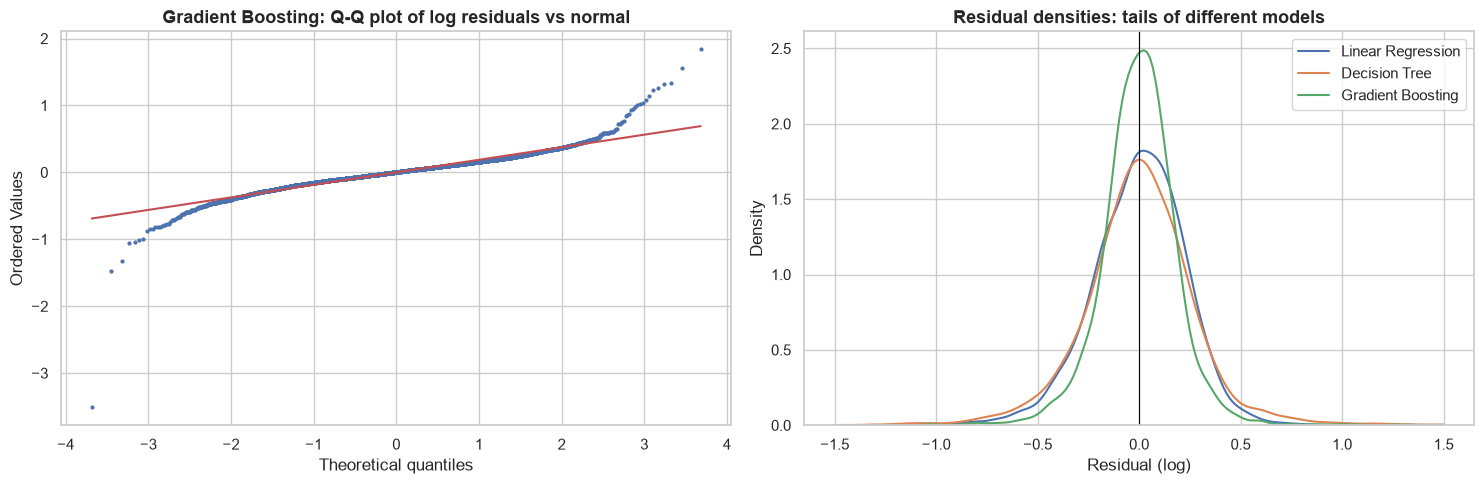

In [23]:
figure, axes = plt.subplots(1, 2, figsize=(15, 5))
stats.probplot(best_errors["Residual_Log"], dist="norm", plot=axes[0])
axes[0].set_title(f"{BEST_REGRESSOR}: Q-Q plot of log residuals vs normal")
axes[0].get_lines()[0].set_markersize(2)
for name in [BASELINE_REGRESSOR, "Decision Tree", BEST_REGRESSOR]:
    sns.kdeplot(log_price - regression_oof[name], ax=axes[1], label=name, clip=(-1.5, 1.5))
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Residual densities: tails of different models")
axes[1].set_xlabel("Residual (log)"); axes[1].legend()
plt.tight_layout()
plt.show()

The Q-Q plot confirms the heavy tails: the central 95% of the residuals follow the normal line closely, but both ends curve away — especially the lower tail (the over-predicted suspicious listings). The density plot shows that Gradient Boosting concentrates far more residuals near zero than the linear model and the single tree.

### 4.5 Regression Discussion

**Relative performance.** Gradient Boosting > SVR ≈ Random Forest > Linear Regression > KNN > Decision Tree on RMSE, MAE and R² (log scale); the ranking is the same on the Lakh scale except that the Lakh metrics are noisier. The typical (median) error drops from ~15% (linear, tree) to ~10% (boosting, forest, SVR).

**Are the assumptions satisfied?**
* *Linearity* — **not** on the raw price (negative predictions, curved residuals); **approximately** on log-price, with remaining curvature in power and at the price extremes.
* *Homoscedasticity* — violated on the Lakh scale; approximately satisfied on the log scale except at the market extremes.
* *Normality of errors* — the centre is normal, the tails are much heavier (kurtosis 14–23).
* *Independence* — **questionable**: the same car appears more than once (re-listed duplicates, Assignment 1), and many cars of the same model/variant share almost identical features and prices, so a random split lets the model see "near copies" of validation cars. The CV scores are therefore somewhat optimistic.

**Bias–variance trade-off.**
* *Linear regression*: high bias (cannot bend), low variance — train and validation error are almost equal (0.240 / 0.243).
* *Decision tree*: low bias but high variance — the validation curve shows the train/validation gap opening after depth ~8; a single tree is the worst model.
* *Random Forest*: averaging 200 trees removes most of the tree's variance (RMSE 0.291 → 0.217).
* *KNN (bonus)*: memorizes the training cars (train error ≈ 0, gap 0.264) — the highest-variance model.
* *Gradient Boosting*: builds shallow trees sequentially to reduce bias, with learning rate and subsampling controlling variance — the smallest train/validation gap among the flexible models (0.052) and the lowest validation error: the best balance here.

**Sensitivity to outliers and noise.** Squared-error models (linear regression, boosting with squared loss) are pulled by extreme prices: the luxury cars dominate the Lakh-scale MSE, and a single mislabeled Porsche creates an error of 66 Lakh. Working on the log scale reduces this sensitivity a lot. Tree ensembles are robust to outliers in the *features* (a split does not care whether km is 700,000 or 6,500,000) but cannot extrapolate beyond the target values they have seen. SVR's ε-insensitive loss makes it one of the most robust models (best median error).

**When do linear models fail — and why?**
1. On the **raw price** (multiplicative depreciation, heteroscedastic noise → negative predictions and a funnel of residuals).
2. When the effect of a feature is **not constant**: power and engine size matter differently for a hatchback than for a luxury SUV; the linear model has to use one slope for all cars.
3. With **interactions** — e.g. age reduces the price of a luxury car by more Lakh than of a budget car; without explicitly engineered interaction terms the linear model cannot express this.

**When do tree-based models help?** They capture non-linearities and interactions automatically (no need to guess the right transformation), ignore the scale of the features, handle skewed features without transformation, and are not affected by extreme feature values. Their weaknesses: no extrapolation (the 160-Lakh Range Rover), a step-shaped prediction function, and the need for enough data in each region — which is exactly why rare brands remain poorly predicted.

**Interpretability vs performance.** Linear regression gives one readable coefficient per feature (e.g. "each year of age reduces the price by ≈ x%") and ~15% typical error. Gradient Boosting reduces the typical error to ~10% and large errors (> 25%) from 30% of cars to 17%, but it is a black box of 400 trees that needs extra tools (feature importance, partial dependence) to explain. For a pricing tool the accuracy gain matters; for explaining the market to a person, the linear model is often enough.

**Preferred model: Gradient Boosting (on log-price).** It is the best or joint-best on every metric, has no systematic bias by age or by predicted value, the lowest share of large errors, and a stable fold-to-fold performance. Its remaining failures (luxury extrapolation, rare brands, inconsistent listings) are mostly caused by the **data**, not by the model choice — no other model does better on them.

**What I learned from the modelling stage.**
* The **formulation** (log vs raw price) mattered more than the choice of algorithm for the linear model — it cut the MAE by 38% and removed all negative prices.
* A single overall metric hides the story: the same model is excellent for 5,000 mass-market cars and poor for 150 rare-brand cars.
* Several of the "worst errors" are actually **errors in the labels** — the model was right. Error analysis is also a data-cleaning tool.

## 5. Classification Models

**Target:** `Is_Expensive` = 1 if the price is above the median (5.64 Lakh), else 0 — a balanced problem (49.9% positives). The same features and pre-processing are used; the folds are **stratified** 5-fold.

| Model | Hyper-parameters |
|---|---|
| **Prior baseline** (`DummyClassifier`) — always outputs the class share of the training fold | `strategy="prior"` |
| **Logistic Regression** (linear baseline) | `C=1.0`, `max_iter=2000` |
| **Decision Tree** | `max_depth=8`, `min_samples_leaf=10` |
| **Random Forest** | `n_estimators=200`, `min_samples_leaf=2`, `max_features="sqrt"` |
| **Gradient Boosting** | `n_estimators=300`, `learning_rate=0.05`, `max_depth=3`, `subsample=0.8` |
| **KNN** *(bonus)* | `n_neighbors=15`, distance-weighted |

The classifiers output a **probability** of being expensive; unless stated otherwise the decision threshold is 0.5.

In [24]:
CLASSIFICATION_MODELS = {
    "Prior baseline": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, max_features="sqrt",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                    subsample=0.8, random_state=RANDOM_STATE),
    "KNN (bonus)": KNeighborsClassifier(n_neighbors=15, weights="distance"),
}
classification_folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def classification_metrics(true_labels, probabilities, threshold: float = 0.5) -> dict:
    """Threshold-dependent and threshold-free metrics."""
    predicted = (probabilities >= threshold).astype(int)
    return {"accuracy": accuracy_score(true_labels, predicted),
            "precision": precision_score(true_labels, predicted, zero_division=0),
            "recall": recall_score(true_labels, predicted, zero_division=0),
            "F1": f1_score(true_labels, predicted, zero_division=0),
            "MCC": matthews_corrcoef(true_labels, predicted),
            "ROC-AUC": roc_auc_score(true_labels, probabilities)}


def cross_validate_classifier(model) -> tuple:
    """Out-of-fold probabilities and per-fold metrics for one classifier."""
    out_of_fold = pd.Series(np.nan, index=cars.index)
    fold_rows = []
    for fold_number, (train_index, valid_index) in enumerate(classification_folds.split(features, is_expensive), start=1):
        fitted = make_pipeline(clone(model)).fit(features.iloc[train_index], is_expensive.iloc[train_index])
        probabilities = fitted.predict_proba(features.iloc[valid_index])[:, 1]
        out_of_fold.iloc[valid_index] = probabilities
        train_auc = roc_auc_score(is_expensive.iloc[train_index], fitted.predict_proba(features.iloc[train_index])[:, 1])
        fold_rows.append({"fold": fold_number, **classification_metrics(is_expensive.iloc[valid_index], probabilities),
                          "train ROC-AUC": train_auc})
    return out_of_fold, pd.DataFrame(fold_rows)


classification_oof, classification_fold_scores = {}, {}
for model_name, model in CLASSIFICATION_MODELS.items():
    start = time.perf_counter()
    classification_oof[model_name], classification_fold_scores[model_name] = cross_validate_classifier(model)
    print(f"{model_name:<20} done in {time.perf_counter() - start:5.1f} s")

classification_summary = pd.DataFrame({name: scores.drop(columns="fold").mean()
                                       for name, scores in classification_fold_scores.items()}).T
classification_std = pd.DataFrame({name: scores.drop(columns="fold").std()
                                   for name, scores in classification_fold_scores.items()}).T
print("\nMean over folds (threshold 0.5):")
display(classification_summary.sort_values("ROC-AUC", ascending=False))
print("Standard deviation over folds:")
display(classification_std.loc[classification_summary.sort_values("ROC-AUC", ascending=False).index])

Prior baseline       done in   0.9 s
Logistic Regression  done in   1.4 s
Decision Tree        done in   1.6 s
Random Forest        done in  11.5 s
Gradient Boosting    done in  29.6 s
KNN (bonus)          done in   8.8 s

Mean over folds (threshold 0.5):


,accuracy,precision,recall,F1,MCC,ROC-AUC,train ROC-AUC
Gradient Boosting,0.922,0.920,0.924,0.922,0.844,0.981,0.990
Random Forest,0.924,0.925,0.923,0.924,0.848,0.980,0.998
Logistic Regression,0.907,0.914,0.899,0.906,0.815,0.972,0.974
KNN (bonus),0.891,0.892,0.890,0.891,0.783,0.961,1.000
Decision Tree,0.891,0.881,0.902,0.892,0.782,0.959,0.978
Prior baseline,0.501,0.000,0.000,0.000,0.000,0.500,0.500


Standard deviation over folds:


,accuracy,precision,recall,F1,MCC,ROC-AUC,train ROC-AUC
Gradient Boosting,0.007,0.010,0.023,0.008,0.015,0.003,0.001
Random Forest,0.009,0.010,0.022,0.010,0.018,0.003,0.000
Logistic Regression,0.009,0.008,0.025,0.011,0.018,0.004,0.001
KNN (bonus),0.011,0.011,0.023,0.012,0.021,0.005,0.000
Decision Tree,0.010,0.010,0.022,0.011,0.020,0.006,0.001
Prior baseline,0.000,0.000,0.000,0.000,0.000,0.000,0.000


**Model comparison.** The prior baseline always predicts the majority class of the training fold ("cheap"), so its accuracy is 50% and its ROC-AUC exactly 0.5 — any real model must beat this. All real models separate cheap and expensive cars well (ROC-AUC 0.96–0.98). **Gradient Boosting has the highest ROC-AUC (0.981)** and Random Forest the highest accuracy/MCC (0.924 / 0.848); the difference between the two (≈ 0.002–0.004) is well inside one fold standard deviation (0.007–0.018), so they are practically tied. Logistic regression is close behind (AUC 0.972, MCC 0.815), and the single decision tree and KNN are the weakest (MCC ≈ 0.78). The **train vs validation ROC-AUC** shows the same bias–variance picture as in regression: logistic regression 0.974 / 0.972 (no over-fitting), Random Forest 0.998 / 0.980 and KNN 1.000 / 0.961 (memorization), Gradient Boosting 0.990 / 0.981 (small gap). Gradient Boosting is used for the detailed analysis because it ranks the cars best (AUC) and is also the best regression model, which allows the two error analyses to be linked.

## 6. Classification Error Analysis
The detailed analysis uses the **best classifier by ROC-AUC**, compared with the **Logistic Regression** baseline where useful.

In [25]:
BEST_CLASSIFIER = classification_summary["ROC-AUC"].idxmax()
BASELINE_CLASSIFIER = "Logistic Regression"
print(f"Best classifier by ROC-AUC: {BEST_CLASSIFIER}")


def build_classification_frame(model_name: str, threshold: float = 0.5) -> pd.DataFrame:
    """Out-of-fold probabilities, predictions and outcome type (TP / TN / FP / FN) per car."""
    frame = cars.copy()
    frame["Probability"] = classification_oof[model_name]
    frame["Predicted"] = (frame["Probability"] >= threshold).astype(int)
    frame["Correct"] = frame["Predicted"] == frame["Is_Expensive"]
    frame["Outcome"] = np.select(
        [(frame["Predicted"] == 1) & (frame["Is_Expensive"] == 1), (frame["Predicted"] == 0) & (frame["Is_Expensive"] == 0),
         (frame["Predicted"] == 1) & (frame["Is_Expensive"] == 0)], ["TP", "TN", "FP"], default="FN")
    frame["Confidence"] = np.maximum(frame["Probability"], 1 - frame["Probability"])
    frame["Distance_From_Threshold_Pct"] = (frame["Price"] / PRICE_MEDIAN - 1) * 100
    return frame


best_classification = build_classification_frame(BEST_CLASSIFIER)
baseline_classification = build_classification_frame(BASELINE_CLASSIFIER)

Best classifier by ROC-AUC: Gradient Boosting


### 6.1 Confusion Matrix Analysis

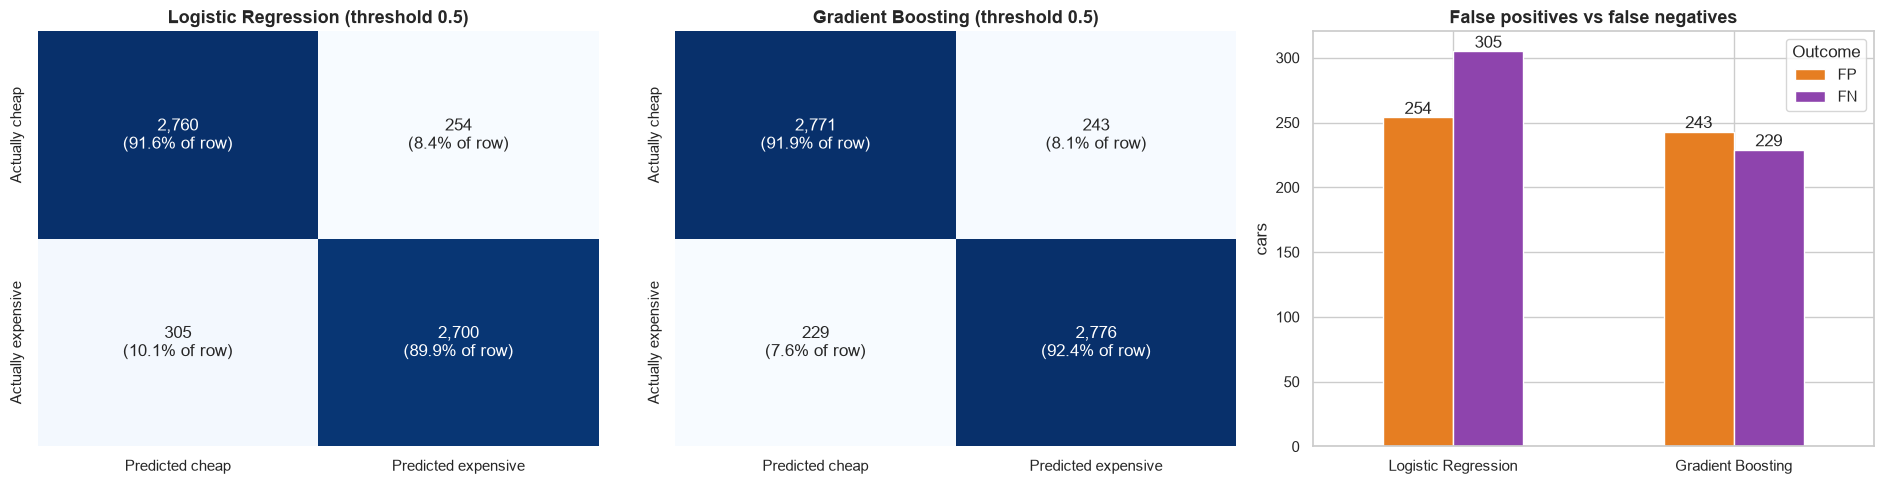

,Logistic Regression,Gradient Boosting
Outcome,,
FN,305,229
FP,254,243
TN,2760,2771
TP,2700,2776


In [26]:
figure, axes = plt.subplots(1, 3, figsize=(19, 5))
for axis, (name, frame) in zip(axes[:2], [(BASELINE_CLASSIFIER, baseline_classification),
                                          (BEST_CLASSIFIER, best_classification)]):
    matrix = confusion_matrix(frame["Is_Expensive"], frame["Predicted"])
    annotations = np.array([[f"{count:,}\n({count / matrix[row].sum():.1%} of row)" for count in matrix[row]]
                            for row in range(2)])
    sns.heatmap(matrix, annot=annotations, fmt="", cmap="Blues", cbar=False, ax=axis,
                xticklabels=["Predicted cheap", "Predicted expensive"], yticklabels=["Actually cheap", "Actually expensive"])
    axis.set_title(f"{name} (threshold 0.5)")

outcome_counts = pd.DataFrame({name: frame["Outcome"].value_counts() for name, frame in
                               [(BASELINE_CLASSIFIER, baseline_classification), (BEST_CLASSIFIER, best_classification)]})
outcome_counts.loc[["FP", "FN"]].T.plot.bar(ax=axes[2], color=["#e67e22", "#8e44ad"])
axes[2].set_title("False positives vs false negatives")
axes[2].set_ylabel("cars"); axes[2].tick_params(axis="x", rotation=0)
for container in axes[2].containers:
    axes[2].bar_label(container)
plt.tight_layout()
plt.show()
outcome_counts

Gradient Boosting: where are the misclassified cars in terms of their TRUE price?
Median distance of misclassified cars from the 5.64 Lakh threshold: 8.1% (correctly classified cars: 49.5%)


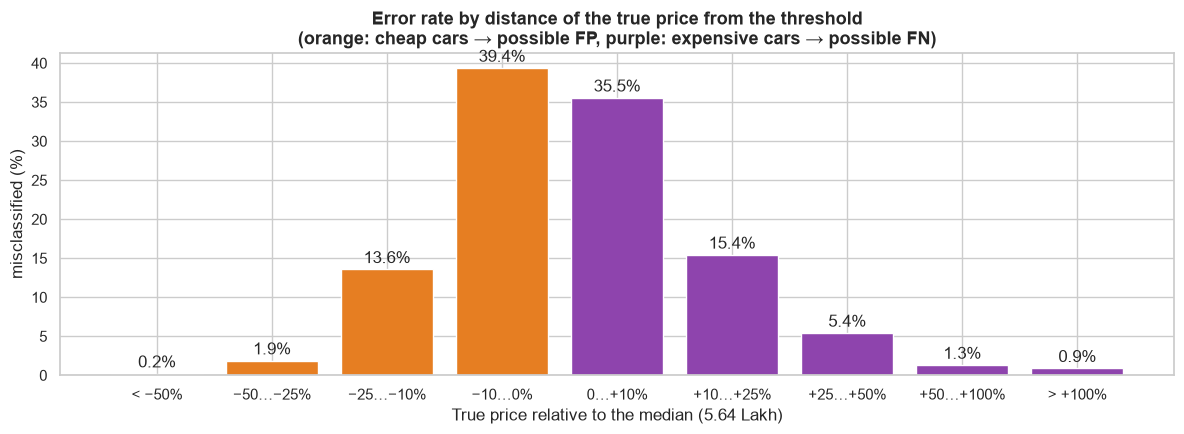

,cars,error_rate_pct,price_range
Distance_Bin,,,
< −50%,979,0.204,0.44–2.81
−50…−25%,1068,1.873,2.83–4.22
−25…−10%,619,13.570,4.23–5.07
−10…0%,348,39.368,5.08–5.64
0…+10%,346,35.549,5.65–6.20
+10…+25%,415,15.422,6.21–7.05
+25…+50%,443,5.418,7.06–8.45
+50…+100%,460,1.304,8.46–11.27
> +100%,1341,0.895,11.31–160.00


In [27]:
print(f"{BEST_CLASSIFIER}: where are the misclassified cars in terms of their TRUE price?")
error_cars = best_classification[~best_classification["Correct"]]
print(f"Median distance of misclassified cars from the 5.64 Lakh threshold: "
      f"{error_cars['Distance_From_Threshold_Pct'].abs().median():.1f}% "
      f"(correctly classified cars: {best_classification.loc[best_classification['Correct'], 'Distance_From_Threshold_Pct'].abs().median():.1f}%)")

DISTANCE_BINS = [-100, -50, -25, -10, 0, 10, 25, 50, 100, 10_000]
DISTANCE_LABELS = ["< −50%", "−50…−25%", "−25…−10%", "−10…0%", "0…+10%", "+10…+25%", "+25…+50%", "+50…+100%", "> +100%"]
best_classification["Distance_Bin"] = pd.cut(best_classification["Distance_From_Threshold_Pct"], DISTANCE_BINS,
                                             labels=DISTANCE_LABELS)
error_by_distance = best_classification.groupby("Distance_Bin", observed=True).agg(
    cars=("Price", "size"), error_rate_pct=("Correct", lambda values: (1 - values.mean()) * 100),
    price_range=("Price", lambda values: f"{values.min():.2f}–{values.max():.2f}"))

figure, axis = plt.subplots(figsize=(12, 4.5))
bars = axis.bar(error_by_distance.index.astype(str), error_by_distance["error_rate_pct"],
                color=["#e67e22" if label.startswith("−") or label.startswith("<") else "#8e44ad"
                       for label in error_by_distance.index.astype(str)])
axis.bar_label(bars, labels=[f"{value:.1f}%" for value in error_by_distance["error_rate_pct"]], padding=2)
axis.set_title("Error rate by distance of the true price from the threshold\n(orange: cheap cars → possible FP, purple: expensive cars → possible FN)")
axis.set_xlabel("True price relative to the median (5.64 Lakh)"); axis.set_ylabel("misclassified (%)")
plt.tight_layout()
plt.show()
error_by_distance

**Interpretation of the confusion matrix (Gradient Boosting, threshold 0.5).**
* 2,771 true negatives and 2,776 true positives: **92.2% accuracy**. Errors are almost perfectly balanced: **243 false positives** (8.1% of cheap cars called expensive) and **229 false negatives** (7.6% of expensive cars called cheap). Logistic regression makes more FN (305) than FP (254) — it is slightly biased toward "cheap".
* **The errors are concentrated around the threshold.** Misclassified cars are typically only **7.8% away from 5.64 Lakh** (correct ones: 49.5%). Within ±10% of the threshold the error rate is **35–40%** — close to a coin flip — while beyond ±50% it is below 2%. The classification errors are therefore mostly *small regression errors that happen to cross the line*.

**Which error is more critical?** It depends on the use. Consider a **used-car platform that uses the model to suggest a price category to sellers**:
* A **false negative** (an expensive car labelled "cheap") can make the seller list the car too low → a direct and irreversible **financial loss** for the seller and a loss of trust in the platform.
* A **false positive** (a cheap car labelled "expensive") leads to an over-priced listing → the car sells more slowly, but the seller can still lower the price later.
In this context **false negatives are the more critical error**, so a threshold below 0.5 should be preferred (Section 6.4). For a *budget buyer* filter ("show me cars I can afford") the priorities reverse.

**Where does the model fail systematically?** (tables below)
* **Mid-aged cars (3–8 years)** — this is where the prices of mass-market cars cross 5.64 Lakh. Very new cars (mostly expensive) and very old cars (almost all cheap) are easy.
* **Manual cars** (9.4% error vs 4.1% for automatics) — automatics are 84% expensive and easy to classify, while manual cars sit on both sides of the threshold.
* **Mid-range brands whose models straddle the threshold** — Volkswagen (15%), Renault, Skoda, Ford (12–14%) and Honda (10.5%). Premium brands (always expensive) and budget brands like Tata are easy.

In [28]:
def error_rate_table(frame: pd.DataFrame, column: str, minimum_cars: int = 30) -> pd.DataFrame:
    """FP rate among cheap cars, FN rate among expensive cars, and overall error rate per group."""
    grouped = frame.groupby(column)
    table = pd.DataFrame({
        "cars": grouped.size(),
        "error rate %": grouped["Correct"].apply(lambda values: (1 - values.mean()) * 100),
        "FP": grouped["Outcome"].apply(lambda values: (values == "FP").sum()),
        "FN": grouped["Outcome"].apply(lambda values: (values == "FN").sum()),
        "share expensive %": grouped["Is_Expensive"].mean() * 100,
    })
    return table[table["cars"] >= minimum_cars].sort_values("error rate %", ascending=False)


best_classification["Age_Group"] = pd.cut(best_classification["Car_Age"], [-1, 2, 5, 8, 12, 25],
                                          labels=["0–2 y", "3–5 y", "6–8 y", "9–12 y", "13+ y"])
for column in ["Age_Group", "Transmission", "Brand"]:
    print(f"\n=== {BEST_CLASSIFIER}: error rate by {column} ===")
    display(error_rate_table(best_classification, column).round(1).head(12))


=== Gradient Boosting: error rate by Age_Group ===


,cars,error rate %,FP,FN,share expensive %
Age_Group,,,,,
3–5 y,2282,10.200,127,106,59.600
6–8 y,1695,7.600,47,81,38.300
0–2 y,987,6.500,49,15,80.600
9–12 y,839,5.100,18,25,22.200
13+ y,216,1.900,2,2,6.000



=== Gradient Boosting: error rate by Transmission ===


,cars,error rate %,FP,FN,share expensive %
Transmission,,,,,
Manual,4299,9.400,203,200,36.200
Automatic,1720,4.000,40,29,84.100



=== Gradient Boosting: error rate by Brand ===


,cars,error rate %,FP,FN,share expensive %
Brand,,,,,
Volkswagen,315,14.900,23,24,34.900
Renault,145,13.800,10,10,45.500
Skoda,173,12.700,12,10,54.300
Ford,300,12.300,22,15,45.300
Mahindra,272,11.400,20,11,73.200
Honda,608,11.000,37,30,39.100
Hyundai,1107,8.700,54,42,35.900
Nissan,91,7.700,1,6,35.200
Toyota,411,7.300,13,17,74.700


**Insight:** the model does not fail in a particular *region of the feature space* so much as in a particular *region of the target*: the cars whose true price is close to the median. Mid-range brands, manual gearboxes and 3–8-year-old cars are simply where most of those borderline cars are.

### 6.2 Probability-Based Analysis

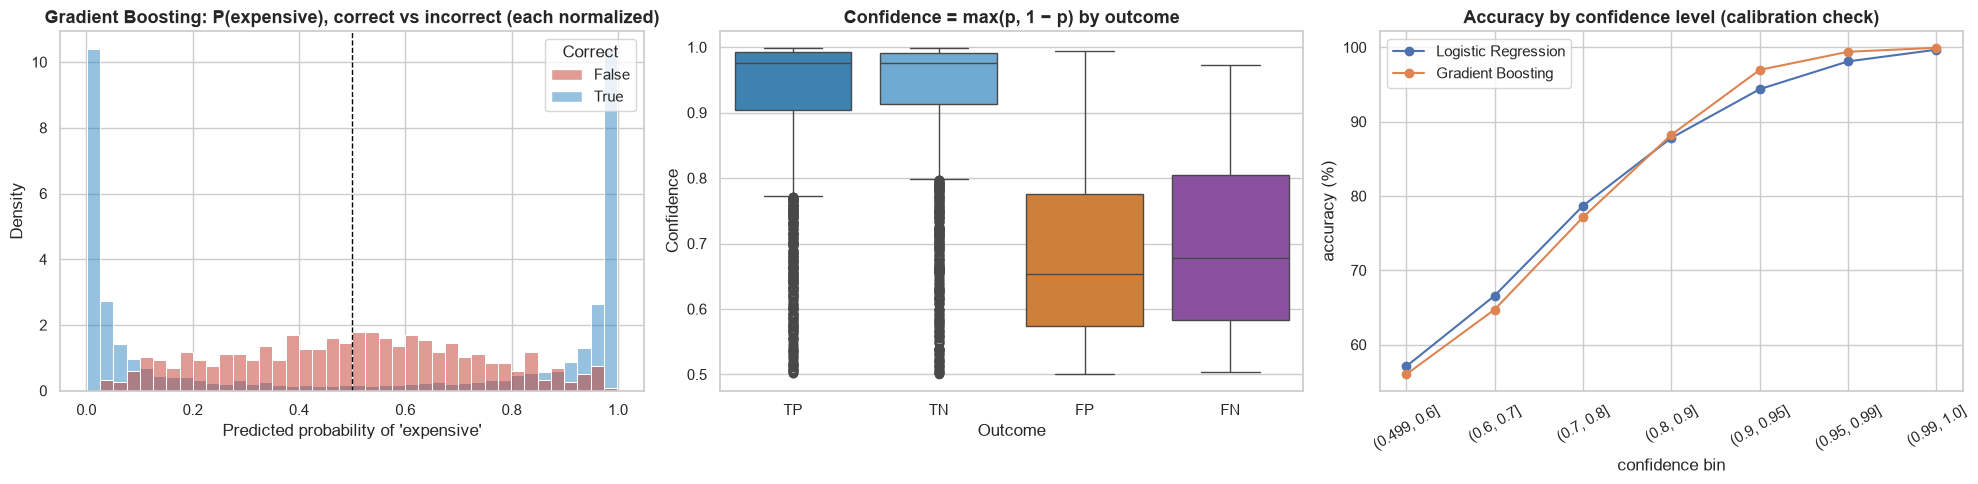

,count,mean,25%,50%,75%
Correct,,,,,
incorrect,472.000,0.689,0.580,0.665,0.790
correct,"5,547.000",0.923,0.909,0.976,0.991


In [29]:
figure, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.histplot(data=best_classification, x="Probability", hue="Correct", bins=40, multiple="layer",
             stat="density", common_norm=False, ax=axes[0], palette={True: "#2e86c1", False: "#c0392b"})
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[0].set_title(f"{BEST_CLASSIFIER}: P(expensive), correct vs incorrect (each normalized)")
axes[0].set_xlabel("Predicted probability of 'expensive'")

sns.boxplot(data=best_classification, x="Outcome", y="Confidence", order=["TP", "TN", "FP", "FN"], ax=axes[1],
            palette={"TP": "#2e86c1", "TN": "#5dade2", "FP": "#e67e22", "FN": "#8e44ad"})
axes[1].set_title("Confidence = max(p, 1 − p) by outcome")

for name in [BASELINE_CLASSIFIER, BEST_CLASSIFIER]:
    frame = build_classification_frame(name)
    confidence_bins = pd.cut(frame["Confidence"], [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0], include_lowest=True)
    accuracy_by_confidence = frame.groupby(confidence_bins, observed=True)["Correct"].mean() * 100
    axes[2].plot(accuracy_by_confidence.index.astype(str), accuracy_by_confidence.values, marker="o", label=name)
axes[2].set_title("Accuracy by confidence level (calibration check)")
axes[2].set_xlabel("confidence bin"); axes[2].set_ylabel("accuracy (%)")
axes[2].tick_params(axis="x", rotation=30); axes[2].legend()
plt.tight_layout()
plt.show()

confidence_summary = best_classification.groupby("Correct")["Confidence"].describe()[["count", "mean", "25%", "50%", "75%"]]
confidence_summary.index = confidence_summary.index.map({True: "correct", False: "incorrect"})
confidence_summary

In [30]:
HIGH_CONFIDENCE = 0.90
high_confidence_errors = best_classification[(~best_classification["Correct"]) &
                                             (best_classification["Confidence"] >= HIGH_CONFIDENCE)].copy()
high_confidence_errors["Tags"] = high_confidence_errors.apply(tag_error_causes, axis=1)
print(f"High-confidence errors (confidence ≥ {HIGH_CONFIDENCE:.0%}): {len(high_confidence_errors)} of "
      f"{(~best_classification['Correct']).sum()} errors")
display(high_confidence_errors.sort_values("Confidence", ascending=False)[
    ["Name", "Year", "Raw_Kilometers", "Power_bhp", "Price", "Probability", "Outcome", "Tags"]].head(15))

near_threshold_share = (high_confidence_errors["Distance_From_Threshold_Pct"].abs() <= 25).mean()
print(f"High-confidence errors whose true price is within ±25% of the threshold: {near_threshold_share:.0%}")
regression_view = best_errors.loc[high_confidence_errors.index, ["Predicted_Price", "Residual_Log"]]
print(f"The same cars in the regression task: median |log residual| = {regression_view['Residual_Log'].abs().median():.2f} "
      f"vs {best_errors['Residual_Log'].abs().median():.2f} for all cars")

High-confidence errors (confidence ≥ 90%): 33 of 472 errors


,Name,Year,Raw_Kilometers,Power_bhp,Price,Probability,Outcome,Tags
S.No.,,,,,,,,
3132,Porsche Cayenne Base,2019,14298,340.000,2.020,0.995,FP,"[implausible price, rare brand]"
2119,Ford Freestyle Titanium Petrol,2007,1261,94.680,6.000,0.027,FN,[rare model]
2428,Mahindra Xylo H4,2015,82000,118.300,4.850,0.972,FP,[]
4324,Honda Jazz 1.5 V i DTEC,2016,35000,98.600,5.500,0.968,FP,[]
4480,Hyundai Xcent 1.1 CRDi SX Option,2014,65000,71.000,6.000,0.033,FN,[]
1017,Volkswagen Vento 1.5 TDI Comfortline,2014,56658,108.500,5.390,0.965,FP,[]
2289,Volkswagen Passat Diesel Highline 2.0 TDI,2011,42500,167.700,5.250,0.961,FP,[]
5373,Maruti Swift Dzire LDI,2017,44504,74.000,5.600,0.959,FP,[]
3031,Maruti Ertiga VXI CNG,2013,53000,80.900,5.800,0.044,FN,[]


High-confidence errors whose true price is within ±25% of the threshold: 79%
The same cars in the regression task: median |log residual| = 0.35 vs 0.10 for all cars


**Findings**
* **Correct predictions are confident, incorrect ones are not.** The median confidence is 0.98 for correct predictions and 0.67 for errors; most errors have probabilities between 0.2 and 0.8. The calibration curve rises steadily — when the model says 95%+ it is right ~99% of the time, and in the 0.5–0.6 band it is right only ~57% of the time. **The probability is a useful warning signal.**
* **High-confidence errors are rare:** 35 of 472 errors (7%) have confidence ≥ 90%. Most of them are ordinary cars priced very close to the threshold (a Honda Jazz at 5.50, a Swift Dzire at 5.60) that the model places slightly on the wrong side with high certainty — cars whose listed price is unusually low or high *for their own description*. 80% of them have a true price within ±25% of the threshold, and in the regression task the same cars have a median |log error| of 0.35 (≈ 42%) vs 0.10 overall.
* The **most confident error** is again the 2019 **Porsche Cayenne listed at 2.02 Lakh** (P(expensive) = 0.995) — the model is right and the label is wrong. High-confidence errors are the best place to look for **data-quality problems**.

### 6.3 Error as a Function of Features

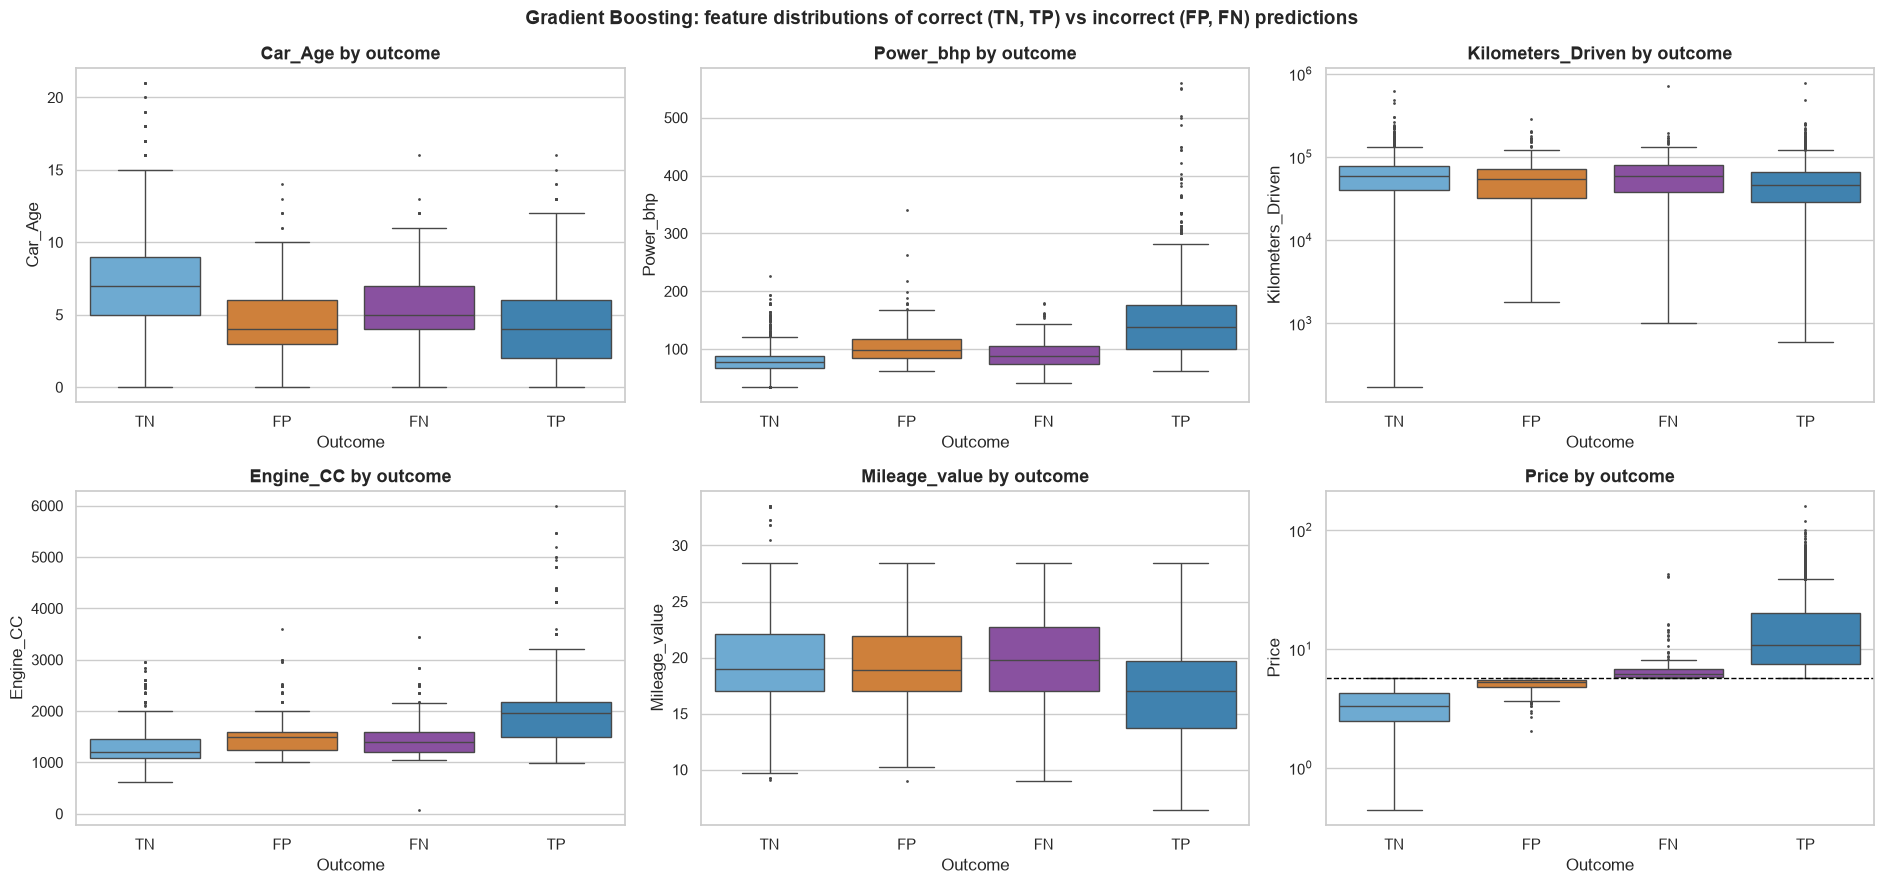

In [31]:
FEATURES_TO_COMPARE = ["Car_Age", "Power_bhp", "Kilometers_Driven", "Engine_CC", "Mileage_value", "Price"]
figure, axes = plt.subplots(2, 3, figsize=(19, 9))
for axis, feature in zip(axes.flat, FEATURES_TO_COMPARE):
    plot_frame = best_classification[[feature, "Outcome"]].dropna()
    sns.boxplot(data=plot_frame, x="Outcome", y=feature, order=["TN", "FP", "FN", "TP"], ax=axis, fliersize=1,
                palette={"TP": "#2e86c1", "TN": "#5dade2", "FP": "#e67e22", "FN": "#8e44ad"})
    if feature in ("Kilometers_Driven", "Price"):
        axis.set_yscale("log")
    if feature == "Price":
        axis.axhline(PRICE_MEDIAN, color="black", linestyle="--", linewidth=1)
    axis.set_title(f"{feature} by outcome")
figure.suptitle(f"{BEST_CLASSIFIER}: feature distributions of correct (TN, TP) vs incorrect (FP, FN) predictions",
                fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Median feature values — correct vs wrong, within each TRUE class:


,cheap: correct,cheap: wrong,expensive: correct,expensive: wrong
Car_Age,7.000,4.000,4.000,5.000
Power_bhp,78.000,98.600,138.100,88.500
Kilometers_Driven,"59,254.000","54,957.000","46,601.000","59,000.000"
Engine_CC,"1,198.000","1,497.000","1,968.000","1,396.000"
Mileage_value,19.000,18.900,17.000,19.795


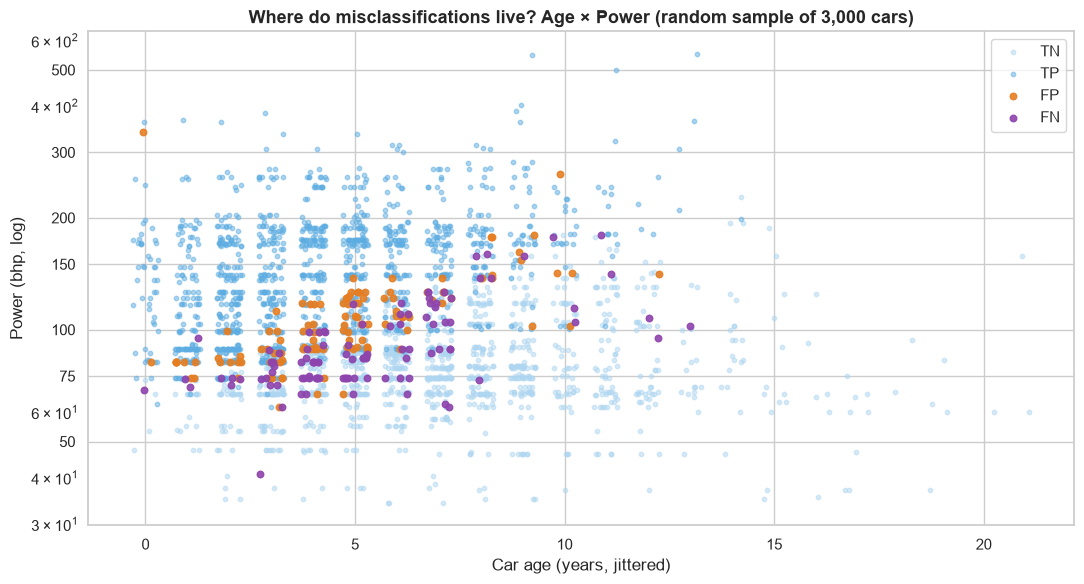

In [32]:
comparison_rows = {}
for feature in ["Car_Age", "Power_bhp", "Kilometers_Driven", "Engine_CC", "Mileage_value"]:
    row = {}
    for true_class, class_name in [(0, "cheap"), (1, "expensive")]:
        subset = best_classification[best_classification["Is_Expensive"] == true_class]
        row[f"{class_name}: correct"] = subset.loc[subset["Correct"], feature].median()
        row[f"{class_name}: wrong"] = subset.loc[~subset["Correct"], feature].median()
    comparison_rows[feature] = row
print("Median feature values — correct vs wrong, within each TRUE class:")
display(pd.DataFrame(comparison_rows).T)

figure, axis = plt.subplots(figsize=(11, 6))
sample = best_classification.sample(3000, random_state=RANDOM_STATE)
for outcome, color in [("TN", "#aed6f1"), ("TP", "#5dade2"), ("FP", "#e67e22"), ("FN", "#8e44ad")]:
    subset = sample[sample["Outcome"] == outcome]
    axis.scatter(subset["Car_Age"] + np.random.default_rng(0).uniform(-0.3, 0.3, len(subset)), subset["Power_bhp"],
                 s=10 if outcome in ("TN", "TP") else 22, alpha=0.5 if outcome in ("TN", "TP") else 0.9,
                 color=color, label=outcome)
axis.set_yscale("log")
axis.set_yticks([50, 75, 100, 150, 200, 300, 500])
axis.get_yaxis().set_major_formatter(plt.ScalarFormatter())
axis.set_title("Where do misclassifications live? Age × Power (random sample of 3,000 cars)")
axis.set_xlabel("Car age (years, jittered)"); axis.set_ylabel("Power (bhp, log)"); axis.legend()
plt.tight_layout()
plt.show()

**Findings — correct vs incorrect predictions**
* **False positives look "too good" for a cheap car:** compared with correctly classified cheap cars they are **younger** (median 4 vs 7 years), have **more power** (99 vs 78 bhp) and **bigger engines** (1,497 vs 1,198 CC) — they have the profile of an expensive car but are listed cheaply.
* **False negatives look "too modest" for an expensive car:** compared with correctly classified expensive cars they have **less power** (88 vs 138 bhp), **smaller engines** (1,396 vs 1,968 CC), are a bit **older** (5 vs 4 years) and have **more km** (59,000 vs 46,600).
* In the Age × Power plot the errors (orange/purple) sit in the **overlap zone** — roughly 3–10 years old and 70–120 bhp — where cheap and expensive cars have the same features. Outside this band (powerful new cars, weak old cars) there are almost no errors.
* **Implication for improvement:** the features that would separate these borderline cars are the ones *missing* from the data — trim level, condition, service history, exact model variant. More data of the same kind will not help much; *different* information will.

### 6.4 Threshold Sensitivity Analysis

In [33]:
threshold_rows = []
for name in CLASSIFICATION_MODELS:
    for threshold in THRESHOLDS:
        threshold_rows.append({"model": name, "threshold": threshold,
                               **classification_metrics(is_expensive, classification_oof[name], threshold)})
threshold_table = pd.DataFrame(threshold_rows)
print(f"{BEST_CLASSIFIER}: metrics at thresholds 0.1 … 0.9 (out-of-fold predictions)")
best_threshold_table = threshold_table[threshold_table["model"] == BEST_CLASSIFIER].drop(columns="model").set_index("threshold")
best_threshold_table["FP"] = [((classification_oof[BEST_CLASSIFIER] >= t) & (is_expensive == 0)).sum() for t in THRESHOLDS]
best_threshold_table["FN"] = [((classification_oof[BEST_CLASSIFIER] < t) & (is_expensive == 1)).sum() for t in THRESHOLDS]
best_threshold_table

Gradient Boosting: metrics at thresholds 0.1 … 0.9 (out-of-fold predictions)


,accuracy,precision,recall,F1,MCC,ROC-AUC,FP,FN
threshold,,,,,,,,
0.100,0.854,0.775,0.995,0.872,0.738,0.981,867,14
0.200,0.892,0.833,0.980,0.901,0.797,0.981,589,59
0.300,0.909,0.868,0.965,0.914,0.824,0.981,440,105
0.400,0.918,0.895,0.946,0.920,0.837,0.981,332,163
0.500,0.922,0.920,0.924,0.922,0.843,0.981,243,229
0.600,0.919,0.942,0.893,0.917,0.839,0.981,166,322
0.700,0.910,0.963,0.851,0.904,0.825,0.981,97,447
0.800,0.891,0.979,0.799,0.880,0.795,0.981,52,605
0.900,0.845,0.991,0.697,0.818,0.723,0.981,19,912


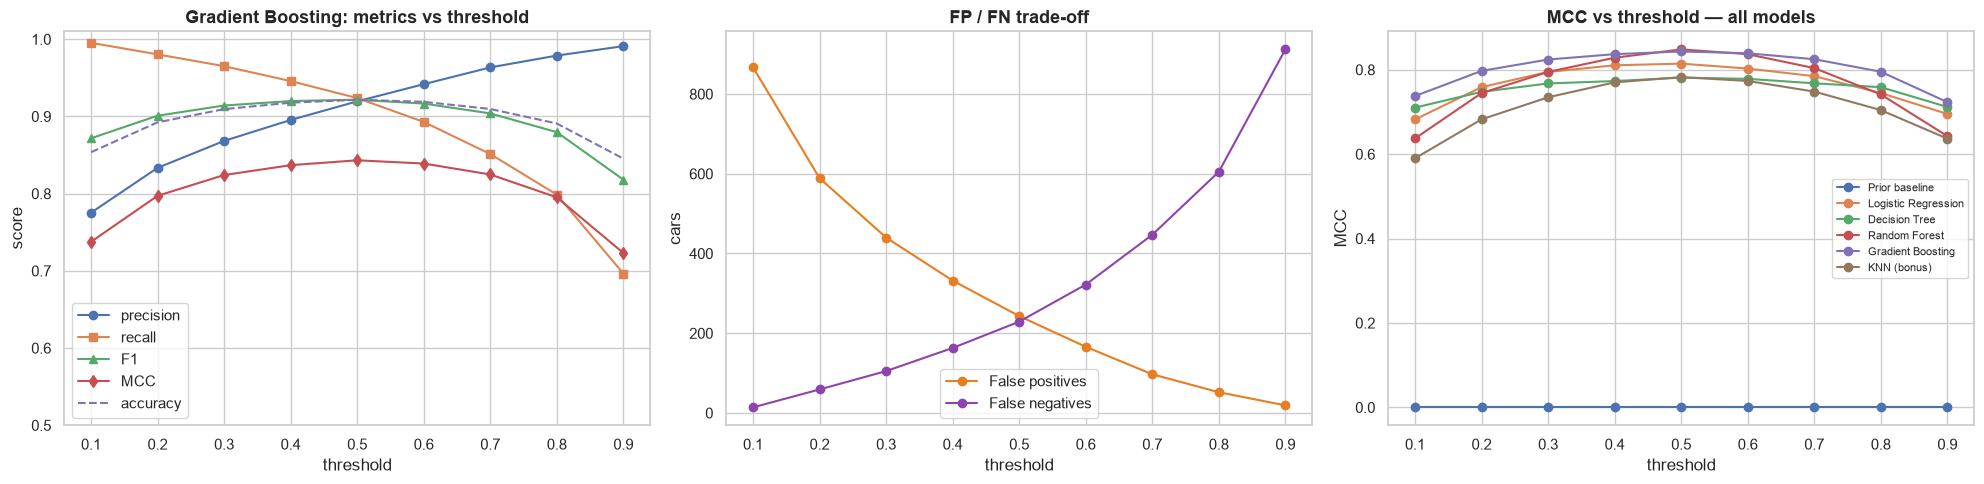

In [34]:
figure, axes = plt.subplots(1, 3, figsize=(20, 5))
for metric, style in [("precision", "-o"), ("recall", "-s"), ("F1", "-^"), ("MCC", "-d"), ("accuracy", "--")]:
    axes[0].plot(best_threshold_table.index, best_threshold_table[metric], style, label=metric)
axes[0].set_title(f"{BEST_CLASSIFIER}: metrics vs threshold")
axes[0].set_xlabel("threshold"); axes[0].set_ylabel("score"); axes[0].legend(); axes[0].set_ylim(0.5, 1.01)

axes[1].plot(best_threshold_table.index, best_threshold_table["FP"], "-o", color="#e67e22", label="False positives")
axes[1].plot(best_threshold_table.index, best_threshold_table["FN"], "-o", color="#8e44ad", label="False negatives")
axes[1].set_title("FP / FN trade-off")
axes[1].set_xlabel("threshold"); axes[1].set_ylabel("cars"); axes[1].legend()

for name in CLASSIFICATION_MODELS:
    subset = threshold_table[threshold_table["model"] == name]
    axes[2].plot(subset["threshold"], subset["MCC"], marker="o", label=name)
axes[2].set_title("MCC vs threshold — all models")
axes[2].set_xlabel("threshold"); axes[2].set_ylabel("MCC"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

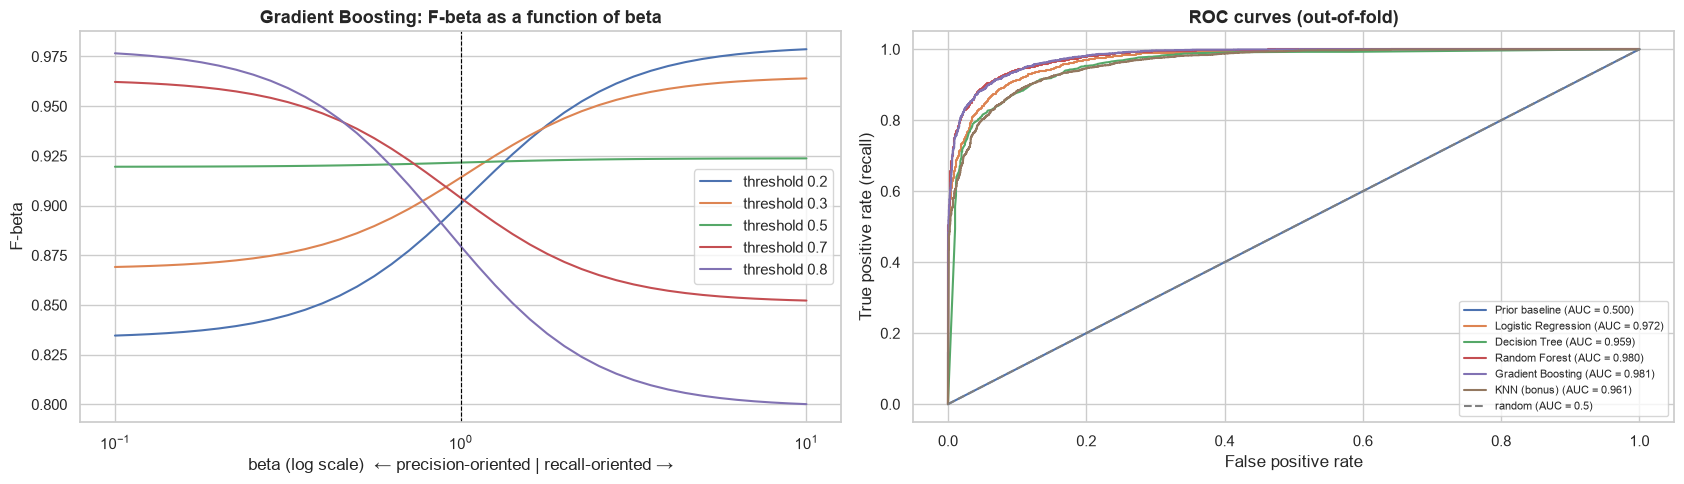

Best threshold for each beta:


,0.500,1.000,2.000
best threshold,0.700,0.500,0.200


In [35]:
BETAS = np.logspace(-1, 1, 41)          # beta from 0.1 (precision matters most) to 10 (recall matters most)
figure, axes = plt.subplots(1, 2, figsize=(17, 5))
for threshold in [0.2, 0.3, 0.5, 0.7, 0.8]:
    predicted = (classification_oof[BEST_CLASSIFIER] >= threshold).astype(int)
    axes[0].plot(BETAS, [fbeta_score(is_expensive, predicted, beta=beta) for beta in BETAS], label=f"threshold {threshold}")
axes[0].set_xscale("log"); axes[0].axvline(1, color="black", linestyle="--", linewidth=0.8)
axes[0].set_title(f"{BEST_CLASSIFIER}: F-beta as a function of beta")
axes[0].set_xlabel("beta (log scale)  ← precision-oriented | recall-oriented →"); axes[0].set_ylabel("F-beta")
axes[0].legend()

for name in CLASSIFICATION_MODELS:
    false_positive_rate, true_positive_rate, _ = roc_curve(is_expensive, classification_oof[name])
    axes[1].plot(false_positive_rate, true_positive_rate,
                 label=f"{name} (AUC = {roc_auc_score(is_expensive, classification_oof[name]):.3f})")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="random (AUC = 0.5)")
axes[1].set_title("ROC curves (out-of-fold)")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (recall)"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

best_beta_threshold = pd.DataFrame({
    beta: {threshold: fbeta_score(is_expensive, (classification_oof[BEST_CLASSIFIER] >= threshold).astype(int), beta=beta)
           for threshold in THRESHOLDS} for beta in [0.5, 1, 2]})
print("Best threshold for each beta:")
best_beta_threshold.idxmax().to_frame("best threshold").T

**Findings — thresholds**
* **Trade-off:** lowering the threshold catches almost every expensive car (recall 0.995 at 0.1) at the cost of many false alarms (869 FP); raising it makes "expensive" predictions almost always right (precision 0.991 at 0.9) but misses 912 expensive cars. FP and FN cross at ≈ 0.5, as expected for a balanced problem with a well-calibrated model.
* **Stable operating region: thresholds 0.3–0.6.** F1 stays between 0.915 and 0.922 and MCC between 0.826 and 0.843 — the choice of threshold hardly matters there. **Unstable regions: below 0.2 and above 0.8**, where each 0.1 step changes MCC by 0.03–0.07 and one type of error explodes. The same shape appears for all models (MCC plot); the stronger models are both higher *and* flatter.
* **F-beta vs beta:** for β < 1 (precision matters more) high thresholds win — the best threshold is 0.7 for β = 0.5; for β > 1 (recall matters more) low thresholds win — the best threshold is 0.2 for β = 2. At β = 1 the curves cross near threshold 0.5. The F-beta plot is a practical tool: **choose β from the business cost of FN vs FP, then read off the threshold.** For the seller-pricing scenario where FN is more costly, β ≈ 2 → **threshold ≈ 0.2–0.3** (recall 0.965–0.981 with precision 0.83–0.87).
* **ROC-AUC** is threshold-free and confirms the ranking: Gradient Boosting 0.981 ≈ Random Forest 0.980 > Logistic Regression 0.972 > KNN 0.961 ≈ Decision Tree 0.959. The curves of the three best models are almost indistinguishable; the tree's curve is visibly "stepped" (few distinct probability values).

### 6.5 Classification Discussion

**Strengths and limitations of the models in relation to the data.**
* All real models achieve > 89% accuracy (vs 50% for the prior baseline) because the classes are largely separable using age, power and brand — the same signals found in the EDA. Tree ensembles (Gradient Boosting, Random Forest) capture interactions such as "powerful *and* new" automatically and are the most accurate and best-ranked.
* Logistic regression is almost as good (AUC 0.972) and far easier to explain, which shows the log-odds of being expensive are close to linear in these features; its weakness is a small bias towards predicting "cheap" (more FN).
* A single tree and KNN are the weakest: the tree gives coarse, step-like probabilities (unstable at extreme thresholds), and KNN suffers from the many one-hot dimensions and the mixed feature scales.

**Key failure modes.**
1. **Borderline cars** — errors are concentrated within ±25% of the threshold; the binary formulation turns small price differences into "wrong" labels.
2. **Feature overlap** — mid-range, mid-age manual cars from brands like Volkswagen, Honda, Ford and Hyundai look the same whether they are listed at 5 or 6.5 Lakh.
3. **Label noise** — a few confident errors are listings with implausible prices.

**Model assumptions vs observed performance.** Logistic regression assumes a linear decision boundary in log-odds; the small gap to the tree ensembles (AUC 0.972 vs 0.981) shows that this assumption is *almost* true here, and the remaining gain comes from interactions. Tree models assume nothing about shape but need data in every region — they do worst where data is scarce (rare brands) and at extreme thresholds, where only a few cars decide the metric.

**Most significant insights.**
* The classifier's errors are a direct consequence of the **problem formulation** (a hard threshold on a continuous price), not of a weak model.
* **Probabilities are well calibrated** and low confidence reliably signals risk — a production system could send uncertain cases (0.3 < p < 0.7) to a human.
* The same cars that are hardest for classification are hard for regression; the two analyses agree.

**Recommendations.**
* Choose the threshold by the business cost (e.g. 0.2–0.3 if false negatives are more costly), not by default.
* Add a "grey zone" class or predict price bands (multi-class / ordinal) instead of a single hard split — or use the regression model and derive the class from the predicted price with a confidence interval.
* Collect the missing information that separates borderline cars (variant/trim, condition, accident and service history).
* Clean the label noise found by the error analysis (implausible prices) and use **grouped CV by car model** to test generalization to unseen models.

## 7. Final Reflection

**1. Where does the model fail most?**
* *Regression:* on **rare and luxury cars** (rare brands: 36% of cars with > 25% error vs 15.5% for mass-market brands; the top 5% money errors are dominated by Mercedes, BMW, Audi, Land Rover), on **very old cars** (> 10 years), and at the **extremes of the price range**, where predictions are pulled towards the average (expensive cars under-predicted, cheap cars over-predicted).
* *Classification:* on **borderline cars** whose true price is within ±10–25% of the 5.64-Lakh threshold (35–40% error rate right at the threshold vs < 2% far from it) — typically 3–8-year-old manual cars from mid-range brands.

**2. Are the failures due to data, model, or formulation?** All three, in different places:
* **Data:** implausible labels (a 2019 Porsche Cayenne at 2 Lakh, a 2019 BMW at 6.7 Lakh), imputed specifications (a Range Rover whose missing power made it look like a small car), and — most importantly — *missing information* (trim level, condition, accident history) that would explain why two similar-looking cars have different prices. Too few examples of rare brands is also a data problem.
* **Model:** the linear model's bias (curvature, no interactions); the single tree's variance; and the tree ensembles' **inability to extrapolate** beyond the most expensive cars they have seen.
* **Formulation:** predicting the raw price caused negative predictions and heteroscedastic errors (fixed by the log target); the **hard median threshold** makes the classification errors near the line almost unavoidable; and random K-fold on data with re-listed cars slightly overstates performance.

**3. What improvements would I propose?**
1. **Data:** clean or flag implausible prices (the error analysis found them); impute missing specifications from the same model rather than the global median; collect variant, condition and service-history features; get more examples of rare brands or model them separately.
2. **Model:** use the **model name** through target encoding (fitted inside the folds) to capture price levels finer than the brand; try a quantile or Huber loss to reduce the influence of mislabeled cars; tune Gradient Boosting with nested CV.
3. **Formulation and evaluation:** keep the log target; report prediction **intervals**, not only point predictions; replace the binary label with price bands or a "grey zone" for uncertain cars; choose the decision threshold from the real cost of FN vs FP (F-beta); use **grouped CV** so the same car or model never appears in both training and validation folds.

**4. What insights did I gain?**
* Good average metrics hide very uneven performance: the models are excellent for the mass market that dominates the data and much weaker for the small groups that are usually the most valuable.
* **Error analysis is a data-quality tool.** Some of the largest "errors" were cases where the model was right and the listing was wrong — the same suspicious listings showed up in the regression, in the classification (as high-confidence errors) and in the EDA of Assignment 1.
* The **way the problem is framed** (log vs raw target, a hard threshold, the choice of *k* and how folds are split) changes the results as much as the choice of algorithm.
* The classification errors are mostly regression errors that crossed a line. Looking at *where* the errors are (near the threshold, in overlapping feature regions) is more useful than the single accuracy number.

## 8. Reproducibility and Automated Checks

* Randomness is fixed (`random_state = 42`) for the folds and for every model that uses randomness.
* All models of a task use **the same features, the same folds and the same pre-processing**; the pre-processing is fitted inside each training fold only.
* Hyper-parameters are written explicitly in Sections 3 and 5. Only the depth of the single tree was chosen with a validation curve; all others were fixed before the analysis.
* The descriptive thresholds used in the error analysis (25% error, confidence ≥ 0.9, the tags in Section 4.3) are diagnostic choices, not tuned parameters.
* The data are the same cleaned listings as in Assignment 1; the 1,234 rows without a price are excluded.

The assertions below verify the main facts the analysis relies on before submission:

In [36]:
assert len(cars) == 6_019 and cars["Price"].notna().all()
assert set(REGRESSION_MODELS) == set(regression_oof) and set(CLASSIFICATION_MODELS) == set(classification_oof)
assert all(predictions.notna().all() for predictions in regression_oof.values()), "every car has an out-of-fold prediction"
assert all(probabilities.between(0, 1).all() for probabilities in classification_oof.values())
assert all(len(scores) == N_FOLDS for scores in regression_fold_scores.values())
assert np.allclose(best_errors["Residual_Log"], log_price - regression_oof[BEST_REGRESSOR]), "residual = y - y_hat"
assert len(extreme_errors) == (best_errors["Abs_Error_Lakh"] >= best_errors["Abs_Error_Lakh"].quantile(0.95)).sum()
assert confusion_matrix(best_classification["Is_Expensive"], best_classification["Predicted"]).sum() == len(cars)
assert regression_summary.loc[BEST_REGRESSOR, "RMSE (log)"] < regression_summary.loc["Mean baseline", "RMSE (log)"]
assert classification_summary.loc[BEST_CLASSIFIER, "ROC-AUC"] > classification_summary.loc["Prior baseline", "ROC-AUC"]
print("All automated checks passed.")

All automated checks passed.
